In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [ ]:
# objective of this project is to predict the crdit consumption rate for the next 3 months

In [ ]:
"""
pipeline followed

load the data
EDA
train test split
missing value imputation
outliers treatment
feature encoding
feature selection
model building
model evaluation
"""

'\npipeline followed\n\nload the data\nEDA\ntrain test split\nmissing value imputation\noutliers treatment\nfeature encoding\nfeature selection\nmodel building\nmodel evaluation\n'

In [ ]:
# import the necessary headers

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestRegressor

from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error, mean_absolute_error

In [ ]:
# load the necessary datasets

In [ ]:
df1 = pd.read_excel('/content/drive/My Drive/Analytix labs case studies/Credit Risk Analysis/CreditConsumptionData.xlsx')
df2 = pd.read_excel('/content/drive/My Drive/Analytix labs case studies/Credit Risk Analysis/CustomerBehaviorData.xlsx')
df3 = pd.read_excel('/content/drive/My Drive/Analytix labs case studies/Credit Risk Analysis/CustomerDemographics.xlsx')

In [ ]:
# check the data heads and the shape

In [ ]:
df1.head()

,ID,cc_cons
0,17051,16239.0
1,11491,39002.0
2,7433,21182.0
3,14606,8123.0
4,8381,28282.0


In [ ]:
df2.head()

,ID,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,...,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active
0,17051,2017.46,29066.66,15919.84,2197.00,3752.000,29798.00,1.0,4,35,...,47,20,41860.0,32734.75,80959.00,36,9,171200.0,Y,3448.84
1,11491,7687.00,1308.00,41888.92,2216.92,7060.530,3143.36,2.0,27,50,...,0,8,113367.0,60974.75,495080.00,5,3,15694.0,Y,3812.69
2,7433,9094.46,14825.95,3087.64,769.59,25602.595,1445.00,44.0,8,47,...,2,14,168000.0,425802.96,115707.38,7,58,28058.0,Y,9432.90
3,14606,3126.00,4616.33,8676.80,5923.00,6717.000,18747.00,4.0,30,1,...,45,44,57750.0,25537.91,63606.00,12,0,24459.0,Y,144.61
4,8381,24988.72,10091.23,10132.00,3477.00,4667.000,511.00,2.0,8,5,...,1,2,18405.0,64687.32,62353.35,49,35,31574.0,Y,1887.89


In [ ]:
df3.head()

,ID,account_type,gender,age,Income,Emp_Tenure_Years,Tenure_with_Bank,region_code,NetBanking_Flag,Avg_days_between_transaction
0,17051,current,M,30,MEDIUM,26.4,9,9,355,0
1,11491,current,M,37,LOW,14.4,7,7,485,0
2,7433,current,M,33,MEDIUM,3.2,1,1,764,0
3,14606,current,M,63,LOW,10.2,6,6,863,0
4,8381,saving,M,33,MEDIUM,26.4,6,6,523,0


In [ ]:
df1.shape

(20000, 2)

In [ ]:
df2.shape

(20000, 39)

In [ ]:
df3.shape

(20000, 10)

In [ ]:
# check for the unique ID values across the datasets

In [ ]:
df1.ID.nunique()

20000

In [ ]:
df2.ID.nunique()

20000

In [ ]:
df3.ID.nunique()

20000

In [ ]:
# chekc for all the column names in each dataset

In [ ]:
df1.columns.to_list()

['ID', 'cc_cons']

In [ ]:
df2.columns.to_list()

['ID',
 'cc_cons_apr',
 'dc_cons_apr',
 'cc_cons_may',
 'dc_cons_may',
 'cc_cons_jun',
 'dc_cons_jun',
 'cc_count_apr',
 'cc_count_may',
 'cc_count_jun',
 'dc_count_apr',
 'dc_count_may',
 'dc_count_jun',
 'card_lim',
 'personal_loan_active',
 'vehicle_loan_active',
 'personal_loan_closed',
 'vehicle_loan_closed',
 'investment_1',
 'investment_2',
 'investment_3',
 'investment_4',
 'debit_amount_apr',
 'credit_amount_apr',
 'debit_count_apr',
 'credit_count_apr',
 'max_credit_amount_apr',
 'debit_amount_may',
 'credit_amount_may',
 'credit_count_may',
 'debit_count_may',
 'max_credit_amount_may',
 'debit_amount_jun',
 'credit_amount_jun',
 'credit_count_jun',
 'debit_count_jun',
 'max_credit_amount_jun',
 'loan_enq',
 'emi_active']

In [ ]:
df3.columns.to_list()

['ID',
 'account_type',
 'gender',
 'age',
 'Income',
 'Emp_Tenure_Years',
 'Tenure_with_Bank',
 'region_code',
 'NetBanking_Flag',
 'Avg_days_between_transaction']

In [ ]:
l1 = df1.columns.to_list()
l2 = df2.columns.to_list()
l3 = df3.columns.to_list()

In [ ]:
s1 = set(l1)
s2 = set(l2)
s3 = set(l3)

In [ ]:
# check for duplicated features

In [ ]:
def check_len(l, s):
  if len(l) == len(s):
    print('True')
  else:
    print('False')

In [ ]:
check_len(l1, s1)

True


In [ ]:
check_len(l2, s2)

True


In [ ]:
check_len(l3, s3)

True


In [ ]:
# therefore there are no duplicated features

In [ ]:
s12 = s2.difference(s1)
s12

{'card_lim',
 'cc_cons_apr',
 'cc_cons_jun',
 'cc_cons_may',
 'cc_count_apr',
 'cc_count_jun',
 'cc_count_may',
 'credit_amount_apr',
 'credit_amount_jun',
 'credit_amount_may',
 'credit_count_apr',
 'credit_count_jun',
 'credit_count_may',
 'dc_cons_apr',
 'dc_cons_jun',
 'dc_cons_may',
 'dc_count_apr',
 'dc_count_jun',
 'dc_count_may',
 'debit_amount_apr',
 'debit_amount_jun',
 'debit_amount_may',
 'debit_count_apr',
 'debit_count_jun',
 'debit_count_may',
 'emi_active',
 'investment_1',
 'investment_2',
 'investment_3',
 'investment_4',
 'loan_enq',
 'max_credit_amount_apr',
 'max_credit_amount_jun',
 'max_credit_amount_may',
 'personal_loan_active',
 'personal_loan_closed',
 'vehicle_loan_active',
 'vehicle_loan_closed'}

In [ ]:
s13 = s3.difference(s1)
s13

{'Avg_days_between_transaction',
 'Emp_Tenure_Years',
 'Income',
 'NetBanking_Flag',
 'Tenure_with_Bank',
 'account_type',
 'age',
 'gender',
 'region_code'}

In [ ]:
s23 = s2.difference(s3)
s23

{'card_lim',
 'cc_cons_apr',
 'cc_cons_jun',
 'cc_cons_may',
 'cc_count_apr',
 'cc_count_jun',
 'cc_count_may',
 'credit_amount_apr',
 'credit_amount_jun',
 'credit_amount_may',
 'credit_count_apr',
 'credit_count_jun',
 'credit_count_may',
 'dc_cons_apr',
 'dc_cons_jun',
 'dc_cons_may',
 'dc_count_apr',
 'dc_count_jun',
 'dc_count_may',
 'debit_amount_apr',
 'debit_amount_jun',
 'debit_amount_may',
 'debit_count_apr',
 'debit_count_jun',
 'debit_count_may',
 'emi_active',
 'investment_1',
 'investment_2',
 'investment_3',
 'investment_4',
 'loan_enq',
 'max_credit_amount_apr',
 'max_credit_amount_jun',
 'max_credit_amount_may',
 'personal_loan_active',
 'personal_loan_closed',
 'vehicle_loan_active',
 'vehicle_loan_closed'}

In [ ]:
# check for the common keys

In [ ]:
s2.intersection(s1)

{'ID'}

In [ ]:
s3.intersection(s1)

{'ID'}

In [ ]:
s2.intersection(s3)

{'ID'}

In [ ]:
# check if the IDs in df1 are same across df2 and df3

In [ ]:
for i in df1.ID:
  if df1.ID[i] == df2.ID[i] and df1.ID[i] == df3.ID[i]:
    print('True')
    break
  else:
    print('False')
    break

True


In [ ]:
# merging all the tables

In [ ]:
df = pd.merge(df1, df2, on = 'ID', how = 'left', validate = 'one_to_one')

In [ ]:
df = pd.merge(df, df3, on = 'ID', how = 'left', validate = 'one_to_one')

In [ ]:
# check the head and the shape of the final dataset

In [ ]:
df.shape

(20000, 49)

In [ ]:
df.head()

,ID,cc_cons,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,...,emi_active,account_type,gender,age,Income,Emp_Tenure_Years,Tenure_with_Bank,region_code,NetBanking_Flag,Avg_days_between_transaction
0,17051,16239.0,2017.46,29066.66,15919.84,2197.00,3752.000,29798.00,1.0,4,...,3448.84,current,M,30,MEDIUM,26.4,9,9,355,0
1,11491,39002.0,7687.00,1308.00,41888.92,2216.92,7060.530,3143.36,2.0,27,...,3812.69,current,M,37,LOW,14.4,7,7,485,0
2,7433,21182.0,9094.46,14825.95,3087.64,769.59,25602.595,1445.00,44.0,8,...,9432.90,current,M,33,MEDIUM,3.2,1,1,764,0
3,14606,8123.0,3126.00,4616.33,8676.80,5923.00,6717.000,18747.00,4.0,30,...,144.61,current,M,63,LOW,10.2,6,6,863,0
4,8381,28282.0,24988.72,10091.23,10132.00,3477.00,4667.000,511.00,2.0,8,...,1887.89,saving,M,33,MEDIUM,26.4,6,6,523,0


In [ ]:
# EDA

In [ ]:
# check for missing values, duplicated records and data types

In [ ]:
df.isna().sum()

,0
ID,0
cc_cons,5000
cc_cons_apr,0
dc_cons_apr,0
cc_cons_may,1
dc_cons_may,1
cc_cons_jun,0
dc_cons_jun,1
cc_count_apr,1
cc_count_may,0


In [ ]:
# there are several missing values also across the target which we will have to predict later

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
# no duplicate records

In [ ]:
df.dtypes

,0
ID,int64
cc_cons,float64
cc_cons_apr,float64
dc_cons_apr,float64
cc_cons_may,float64
dc_cons_may,float64
cc_cons_jun,float64
dc_cons_jun,float64
cc_count_apr,float64
cc_count_may,int64


In [ ]:
df.head()

,ID,cc_cons,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,...,emi_active,account_type,gender,age,Income,Emp_Tenure_Years,Tenure_with_Bank,region_code,NetBanking_Flag,Avg_days_between_transaction
0,17051,16239.0,2017.46,29066.66,15919.84,2197.00,3752.000,29798.00,1.0,4,...,3448.84,current,M,30,MEDIUM,26.4,9,9,355,0
1,11491,39002.0,7687.00,1308.00,41888.92,2216.92,7060.530,3143.36,2.0,27,...,3812.69,current,M,37,LOW,14.4,7,7,485,0
2,7433,21182.0,9094.46,14825.95,3087.64,769.59,25602.595,1445.00,44.0,8,...,9432.90,current,M,33,MEDIUM,3.2,1,1,764,0
3,14606,8123.0,3126.00,4616.33,8676.80,5923.00,6717.000,18747.00,4.0,30,...,144.61,current,M,63,LOW,10.2,6,6,863,0
4,8381,28282.0,24988.72,10091.23,10132.00,3477.00,4667.000,511.00,2.0,8,...,1887.89,saving,M,33,MEDIUM,26.4,6,6,523,0


In [ ]:
# investifate whether any numerical features should be treated as categorical features

In [ ]:
df.personal_loan_active.value_counts()

,count
personal_loan_active,
1,20000


In [ ]:
df.personal_loan_active.nunique()

1

In [ ]:
df.vehicle_loan_active.value_counts()

,count
vehicle_loan_active,
1,20000


In [ ]:
df.vehicle_loan_active.nunique()

1

In [ ]:
df.personal_loan_closed.value_counts()

,count
personal_loan_closed,
1.0,19999


In [ ]:
df.personal_loan_closed.nunique()

1

In [ ]:
df.vehicle_loan_closed.value_counts()

,count
vehicle_loan_closed,
1,20000


In [ ]:
df.vehicle_loan_closed.nunique()

1

In [ ]:
df.loan_enq.value_counts()

,count
loan_enq,
Y,19998


In [ ]:
df.loan_enq.nunique()

1

In [ ]:
# check the categorical features

In [ ]:
df.gender.value_counts()

,count
gender,
M,17287
F,2712
0,1


In [ ]:
df.Income.value_counts()

,count
Income,
MEDIUM,12774
LOW,5612
HIGH,1613
0,1


In [ ]:
df.region_code.value_counts()

,count
region_code,
7,2101
10,2033
2,2033
4,2032
6,2003
1,1986
3,1980
8,1966
5,1944


In [ ]:
df.Avg_days_between_transaction.value_counts()

,count
Avg_days_between_transaction,
1,14360
0,5640


In [ ]:
df.account_type.value_counts()

,count
account_type,
current,16925
saving,3074
0,1


In [ ]:
df.select_dtypes(include = 'object')

,loan_enq,account_type,gender,Income
0,Y,current,M,MEDIUM
1,Y,current,M,LOW
2,Y,current,M,MEDIUM
3,Y,current,M,LOW
4,Y,saving,M,MEDIUM
...,...,...,...,...
19995,Y,current,M,MEDIUM
19996,Y,current,M,MEDIUM
19997,Y,current,M,HIGH
19998,Y,current,M,MEDIUM


In [ ]:
# It can be confirmed that these columns:
#'personal_loan_active',
#'vehicle_loan_active',
#'personal_loan_closed',
#'vehicle_loan_closed',
#'loan_enq'
# have no varaince and don't provide useful information towards the prediction of the target feature
# we will be dropping them during data preparation phase

In [ ]:
# univariate analysis of all the numerical features

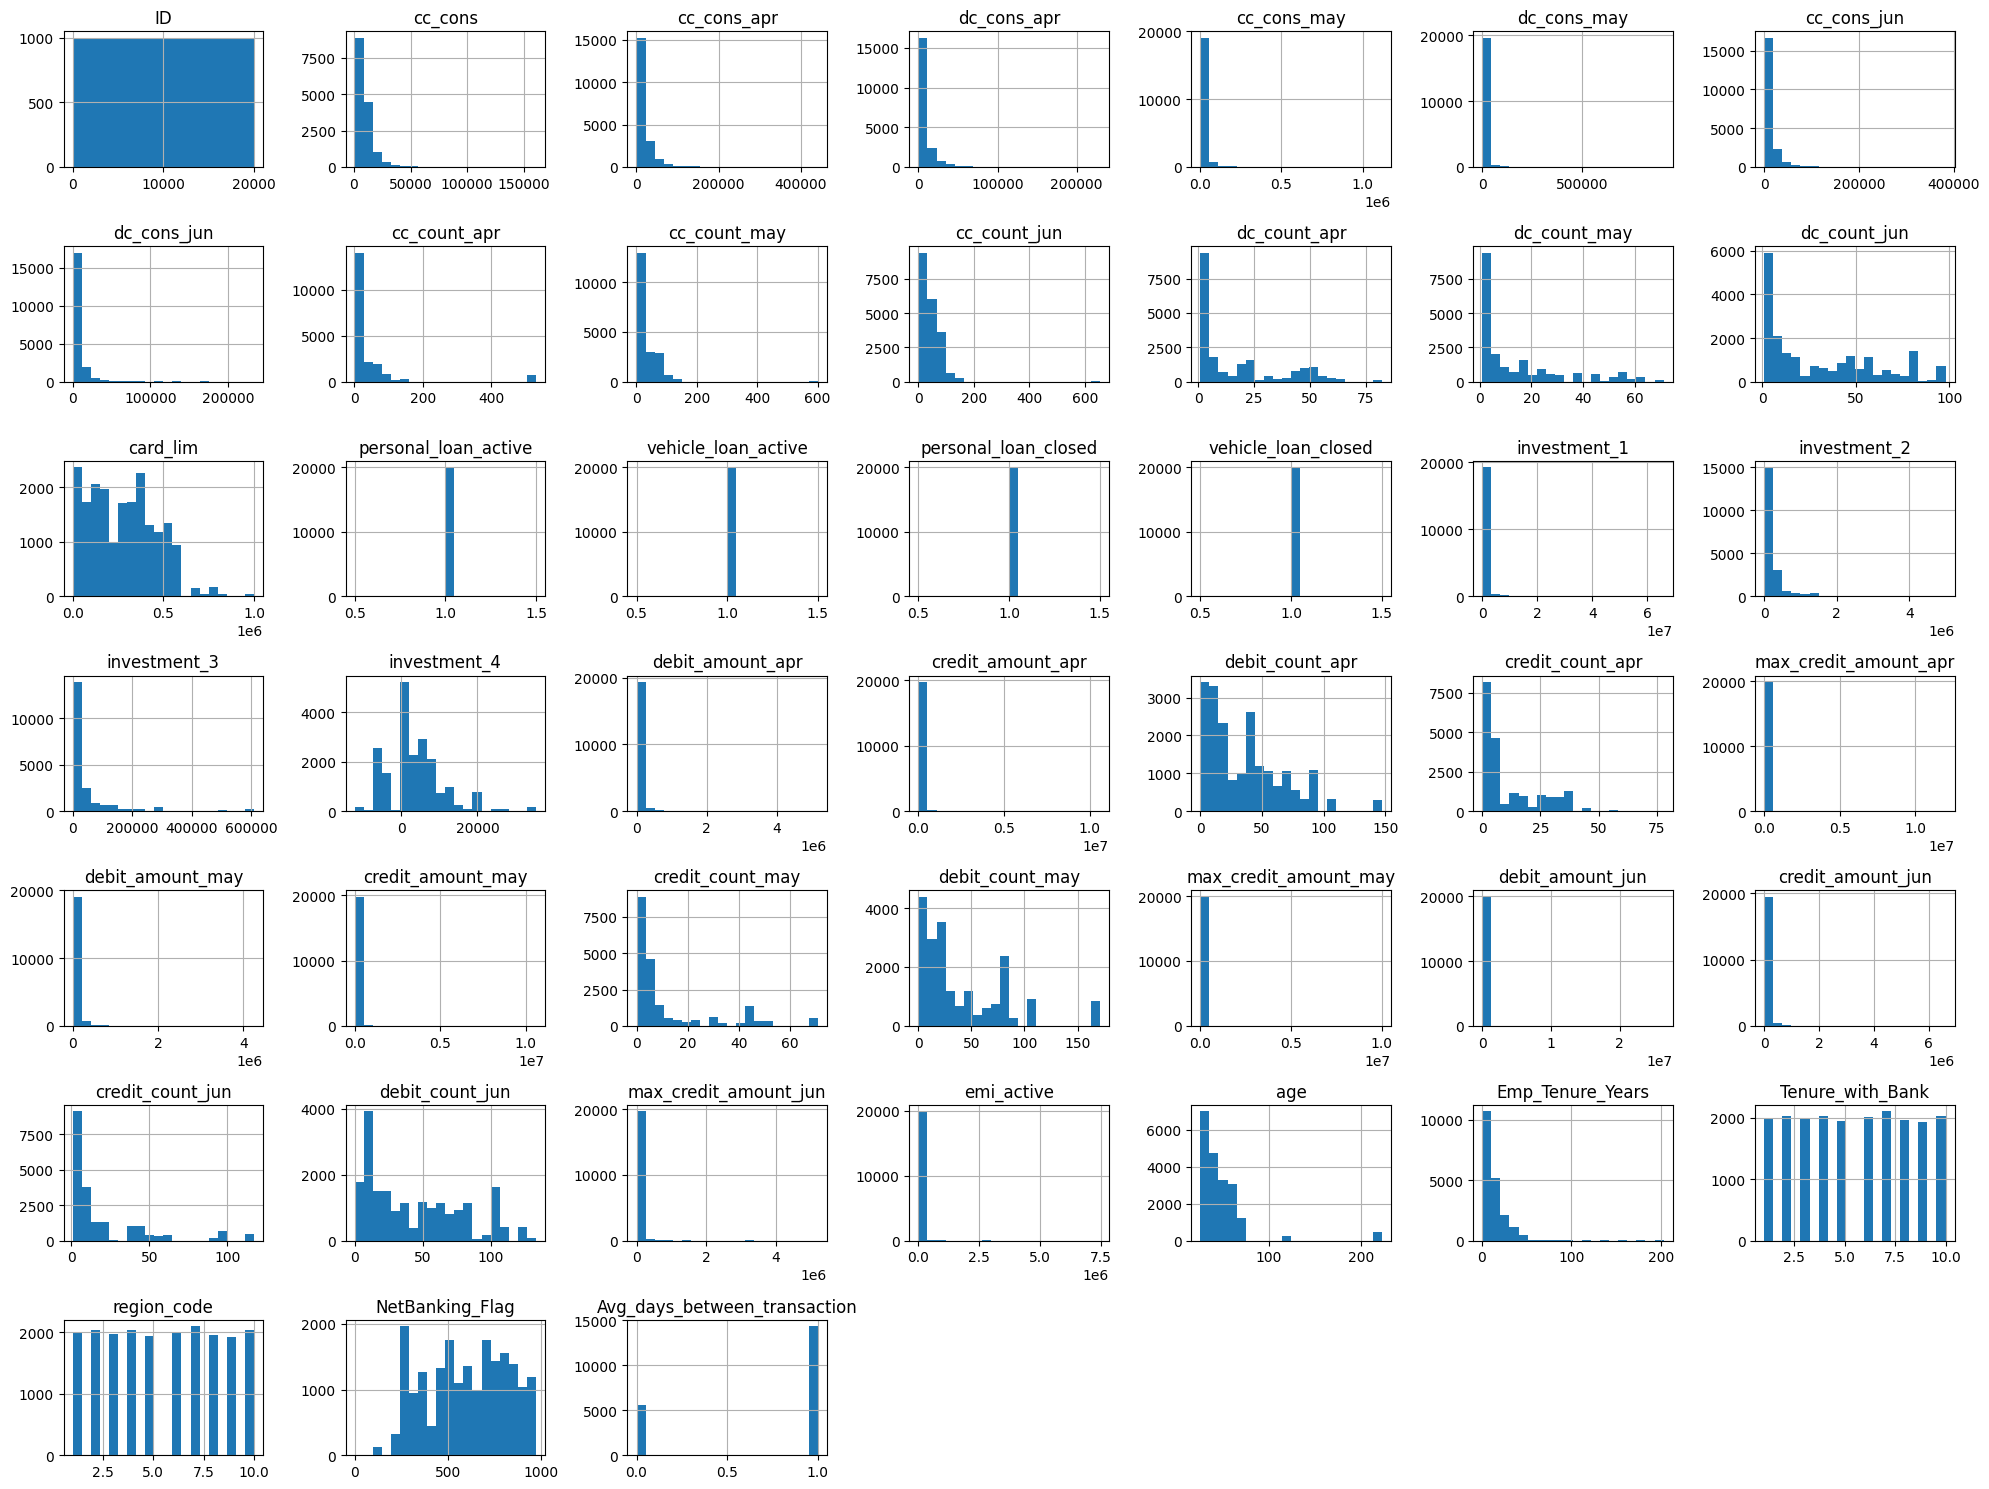

In [ ]:
df.select_dtypes(include = 'number').hist(figsize = (20, 15), bins = 20)
plt.tight_layout()
plt.show()

In [ ]:
df.select_dtypes(include = 'number').skew().sort_values()

,0
Avg_days_between_transaction,-0.969019
NetBanking_Flag,-0.119140
ID,0.000000
personal_loan_active,0.000000
vehicle_loan_closed,0.000000
vehicle_loan_active,0.000000
personal_loan_closed,0.000000
Tenure_with_Bank,0.003167
region_code,0.003167
card_lim,0.450068


In [ ]:
# values > 0, right skewed
# values < 0, left skewed
# values = 0, symmetrical distribution

In [ ]:
# check the outliers

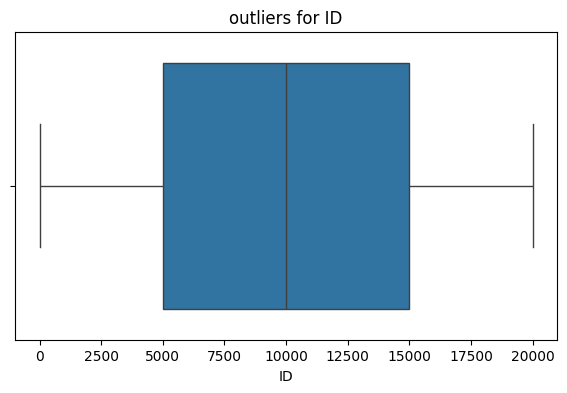

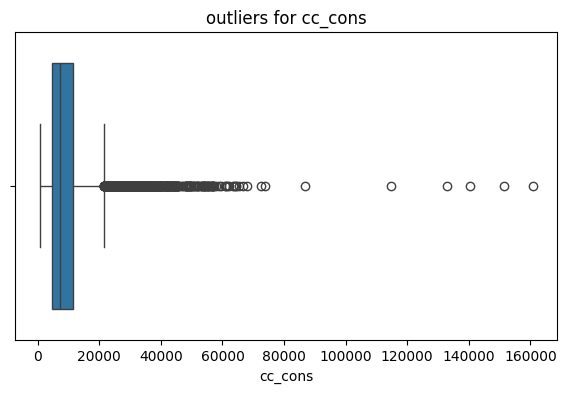

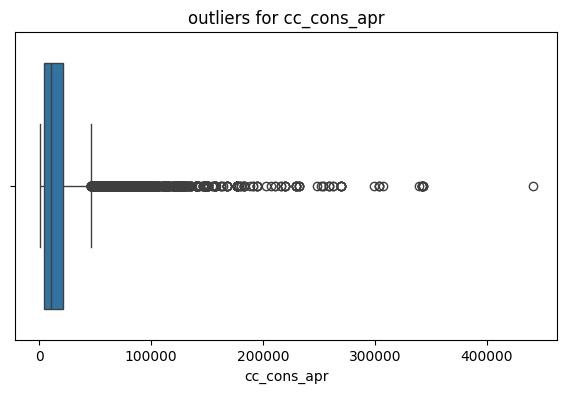

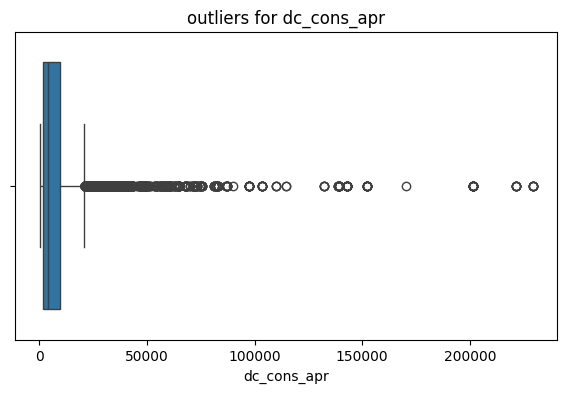

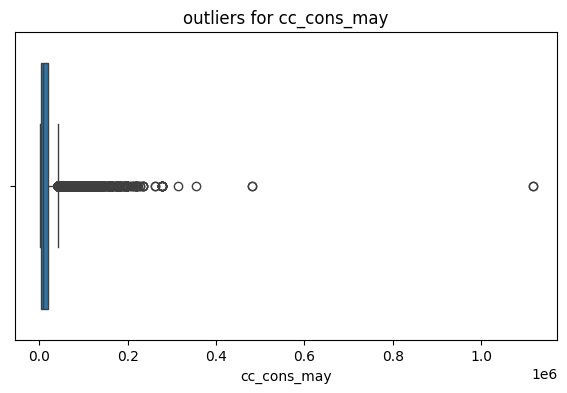

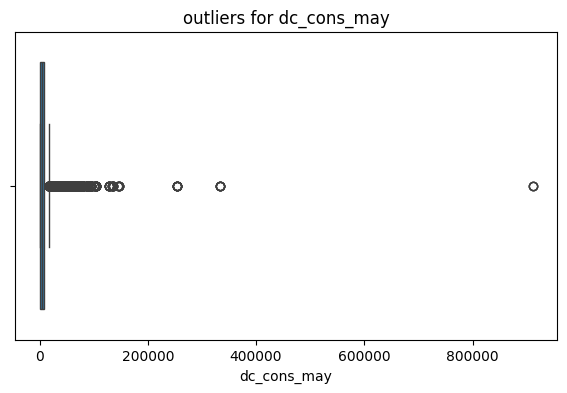

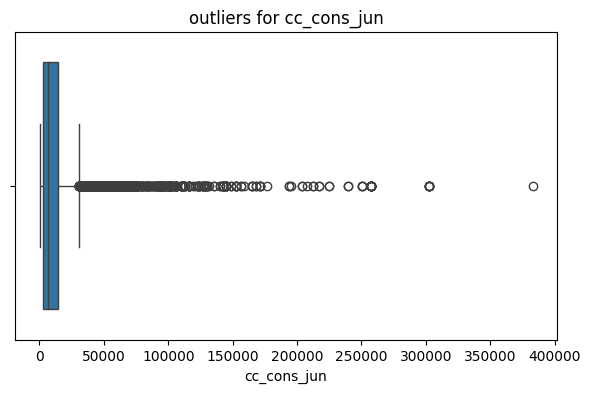

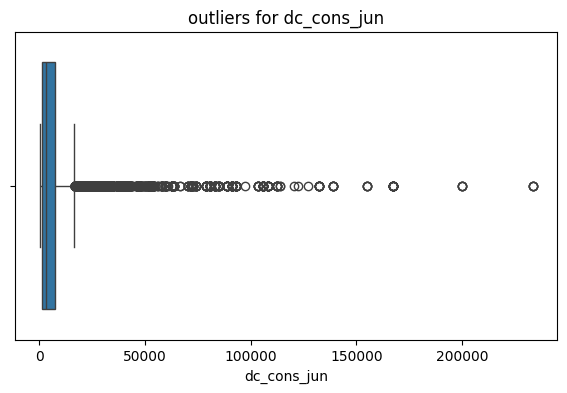

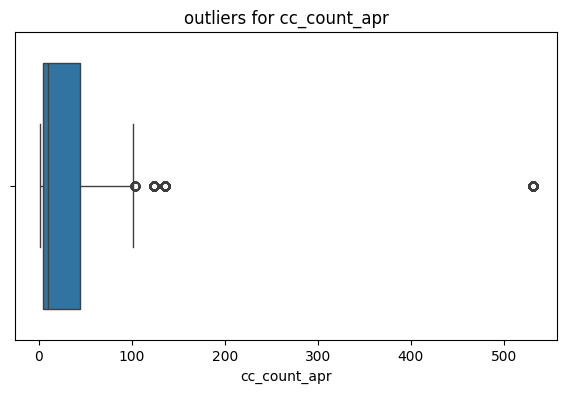

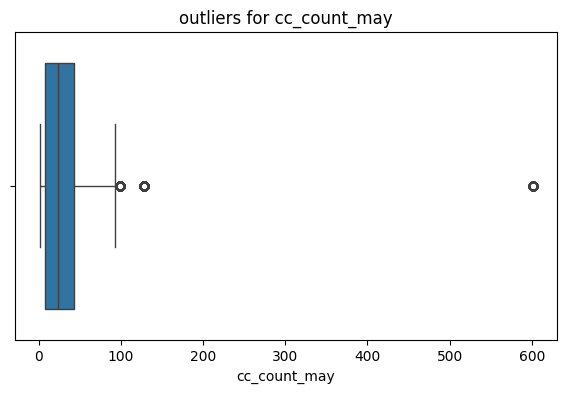

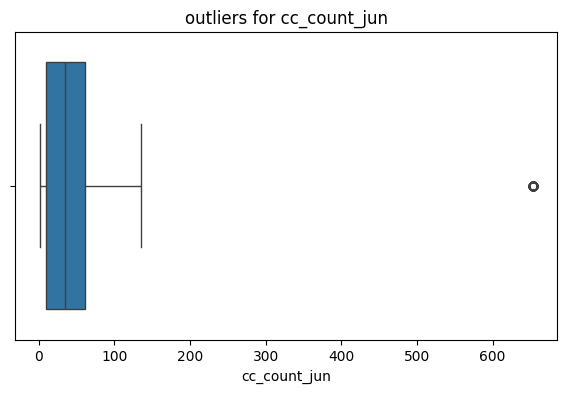

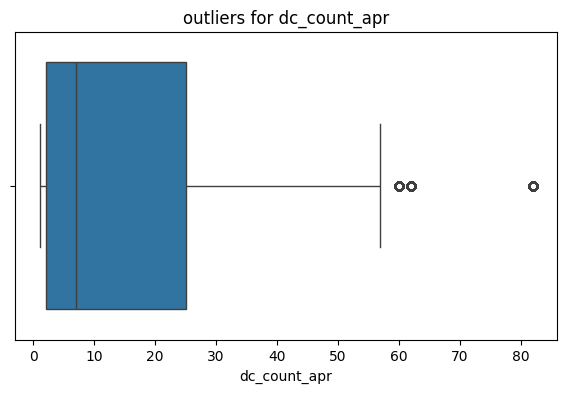

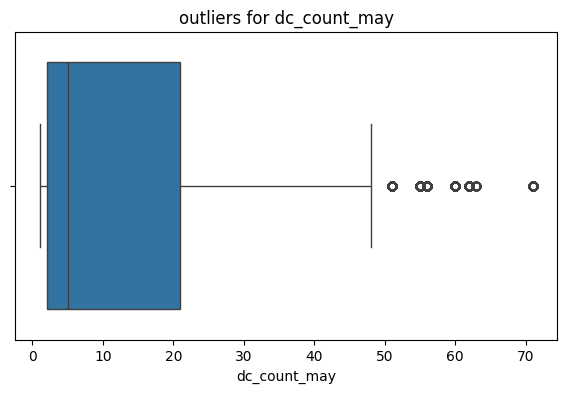

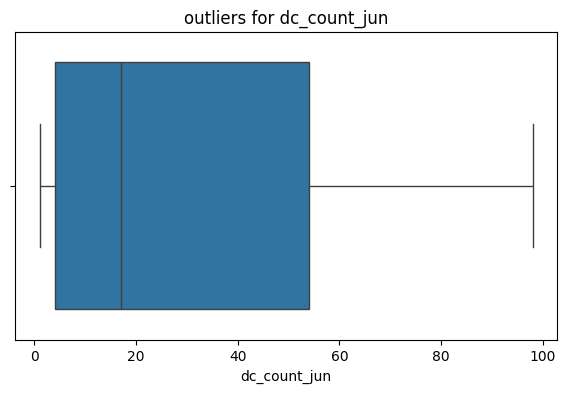

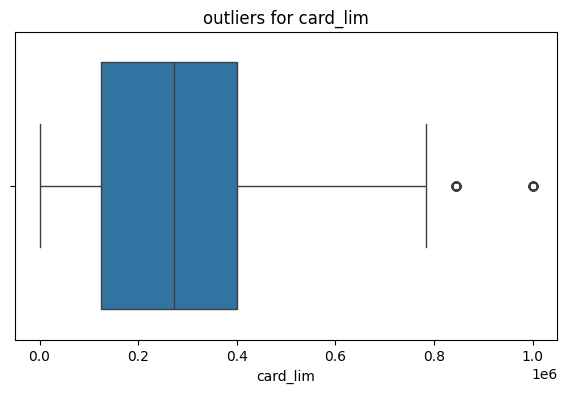

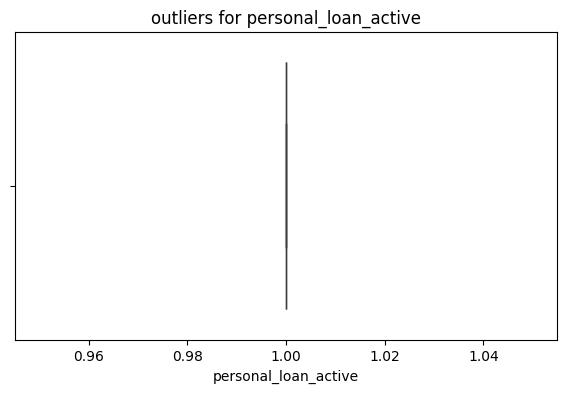

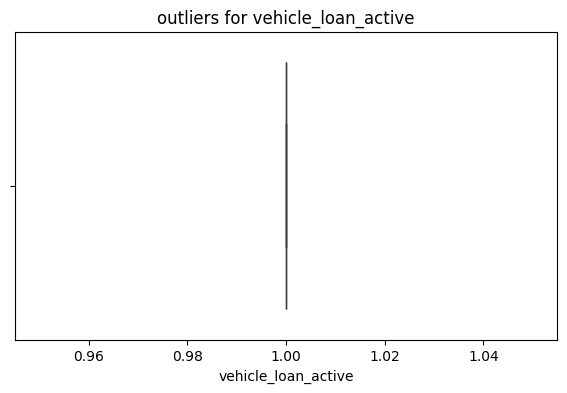

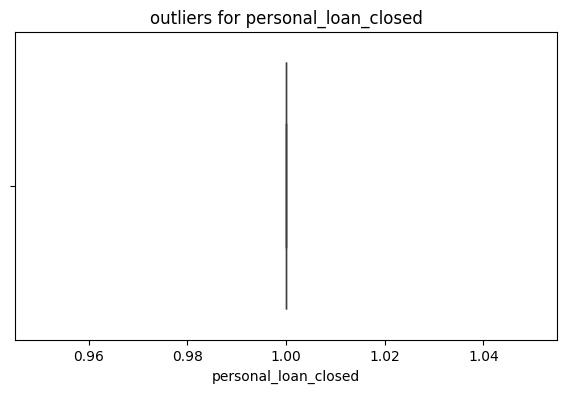

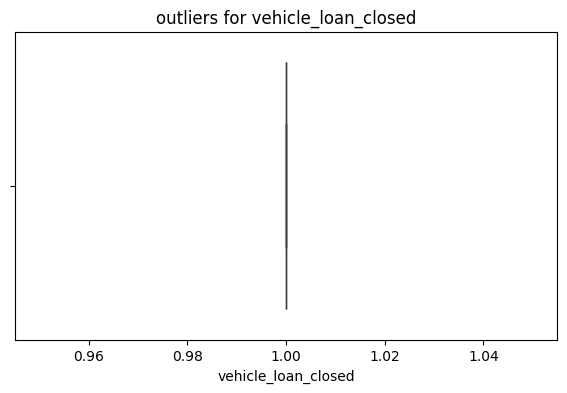

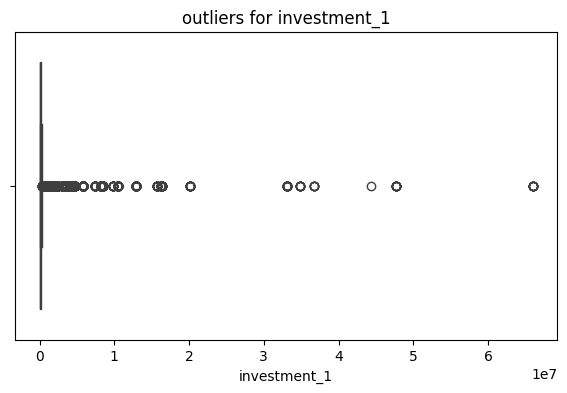

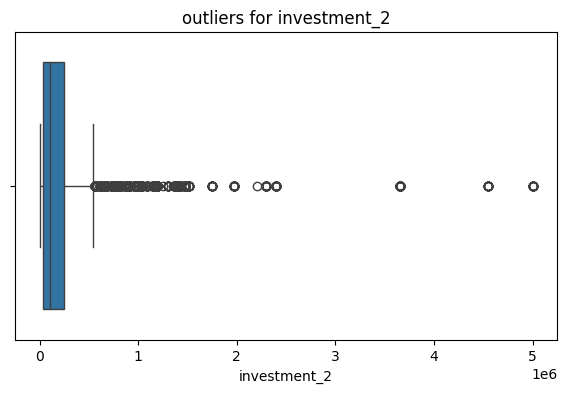

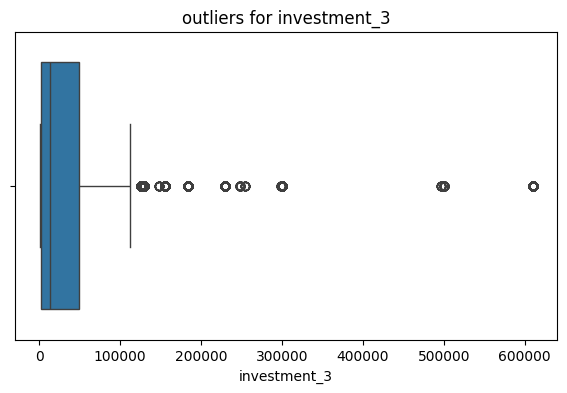

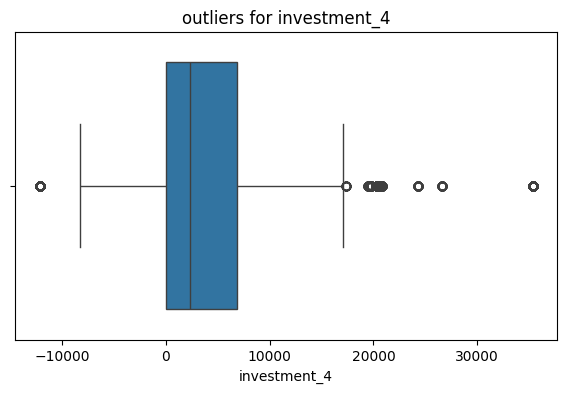

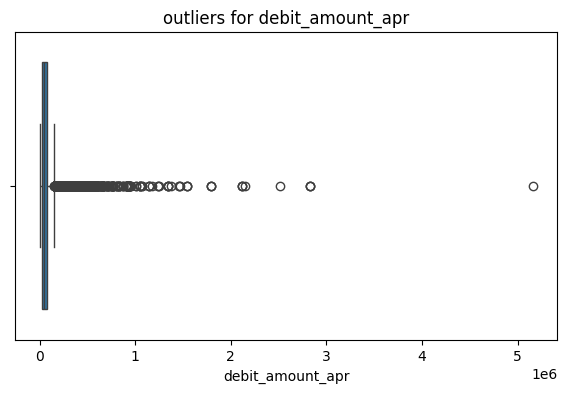

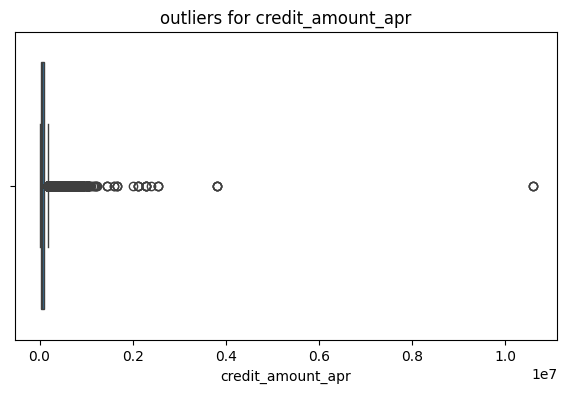

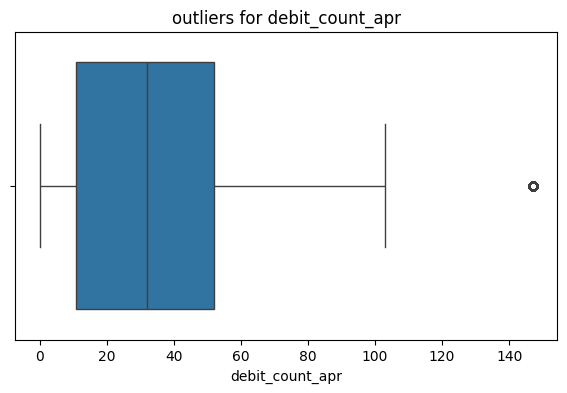

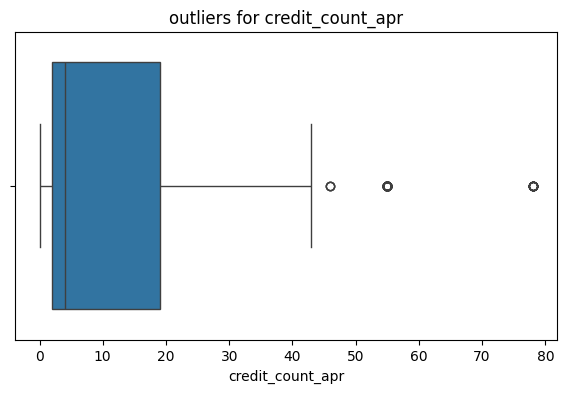

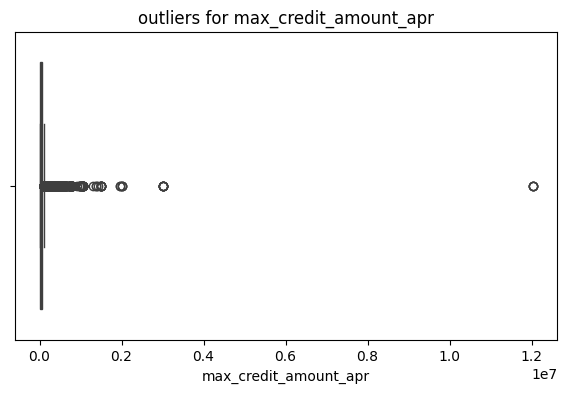

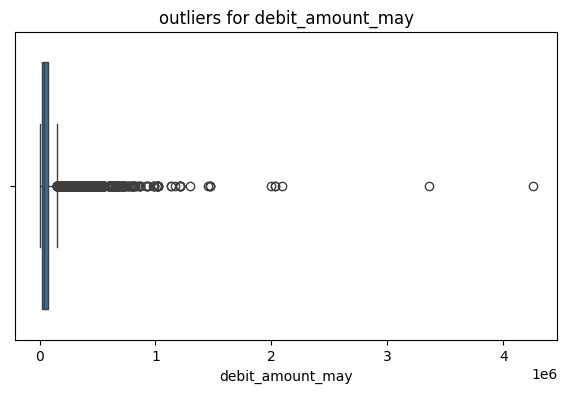

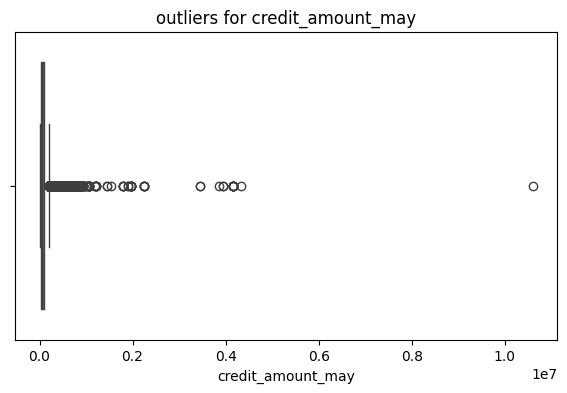

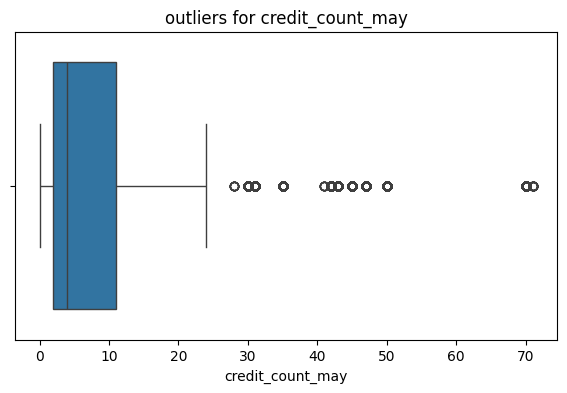

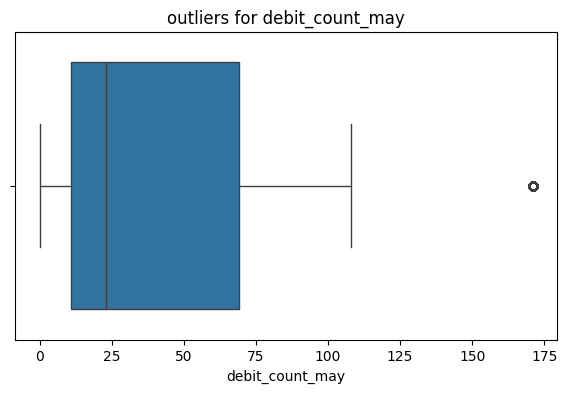

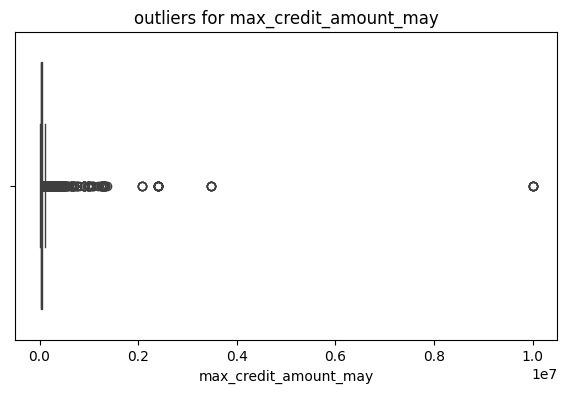

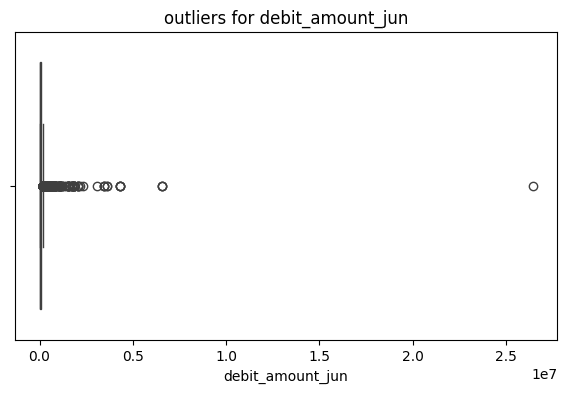

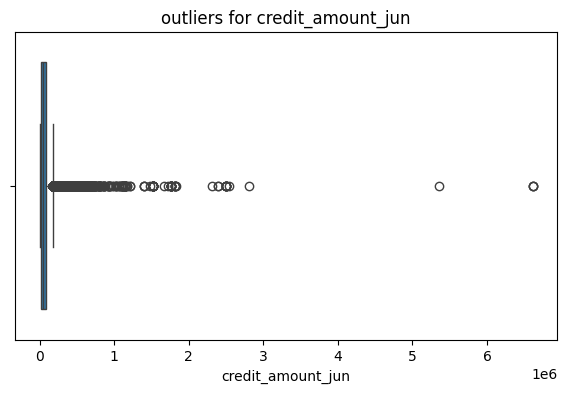

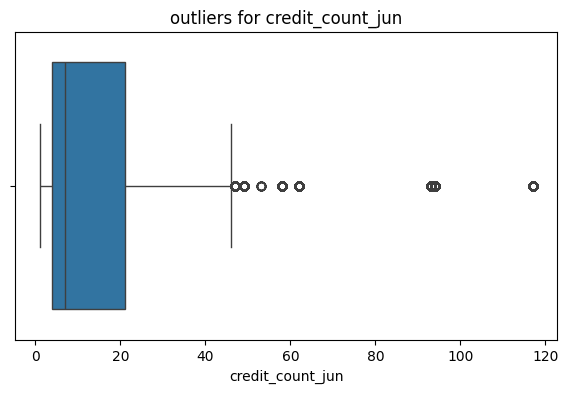

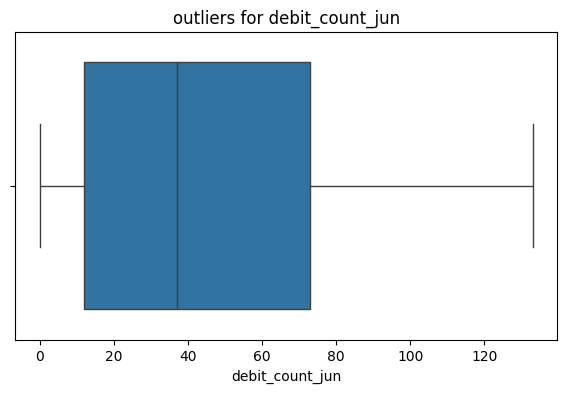

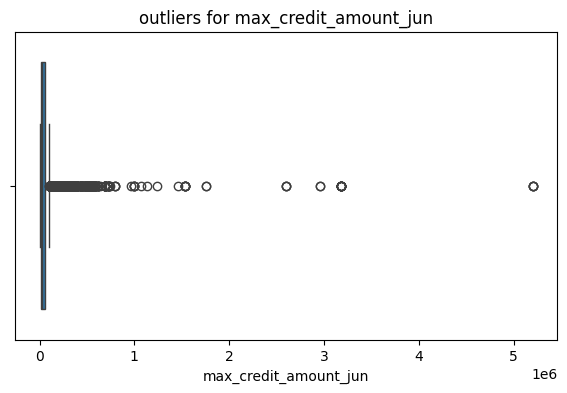

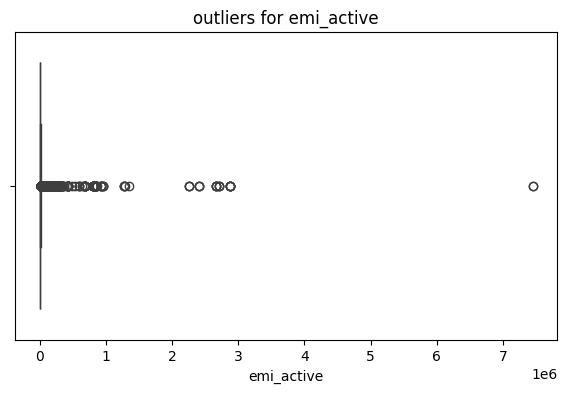

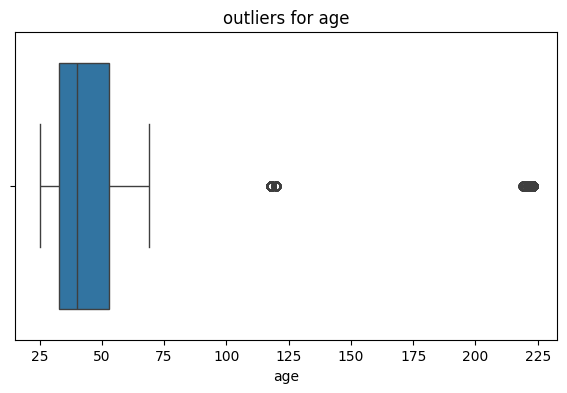

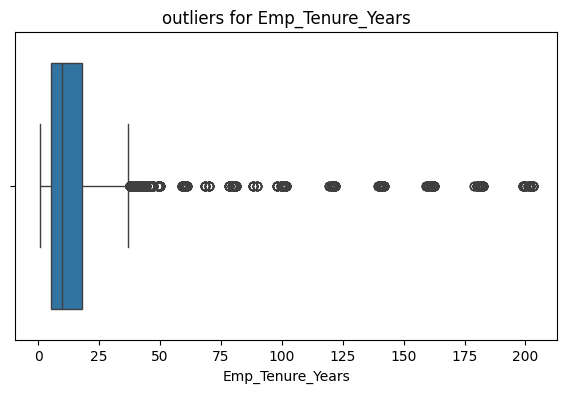

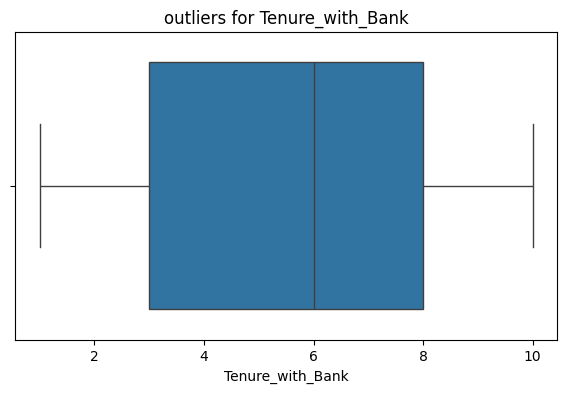

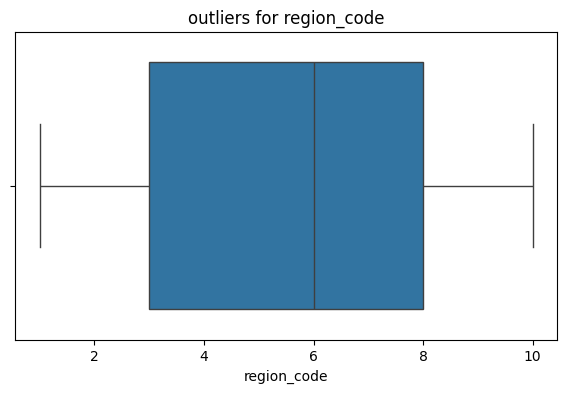

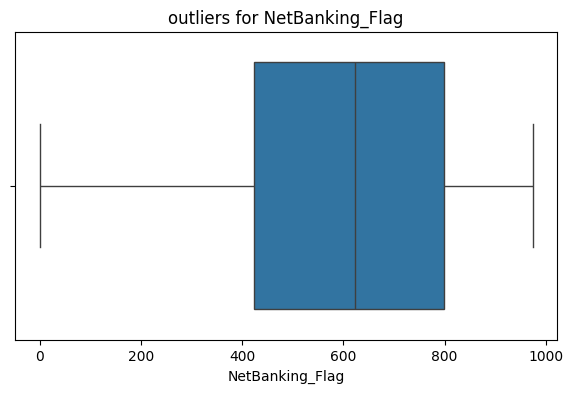

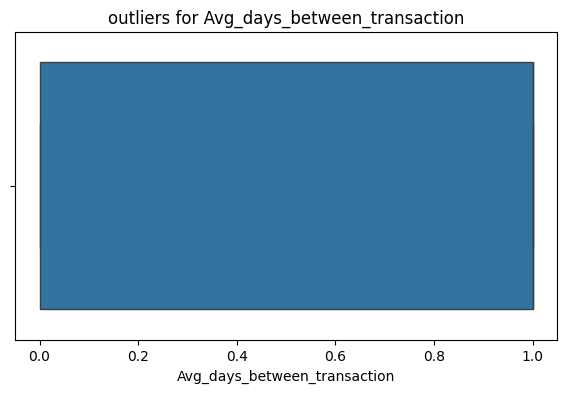

In [ ]:
for col in df.select_dtypes(include = 'number'):
  plt.figure(figsize = (7, 4))
  sns.boxplot(data = df, x = col)
  plt.title(f'outliers for {col}')
  plt.show()

In [ ]:
# visualize the categorical features:

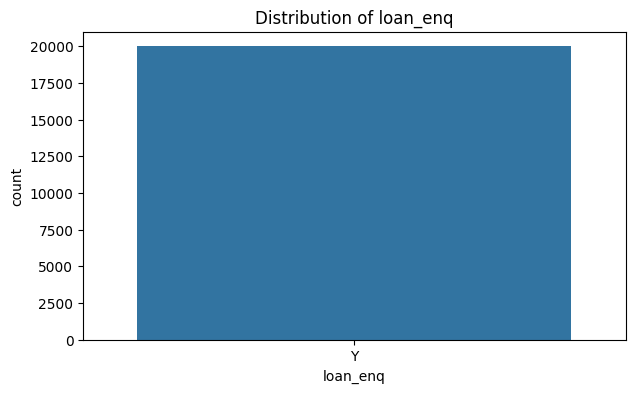

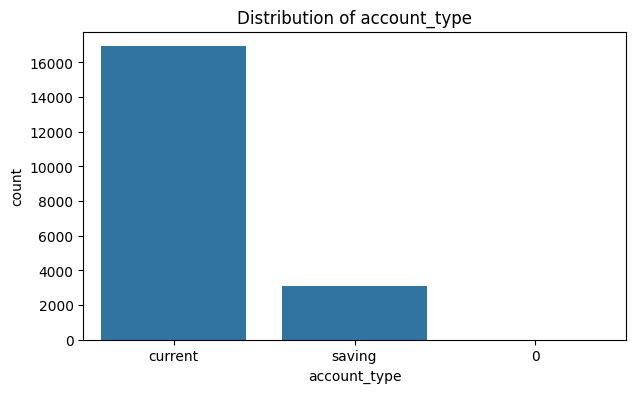

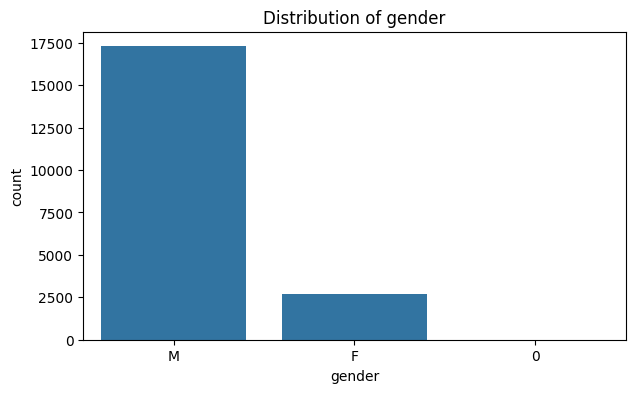

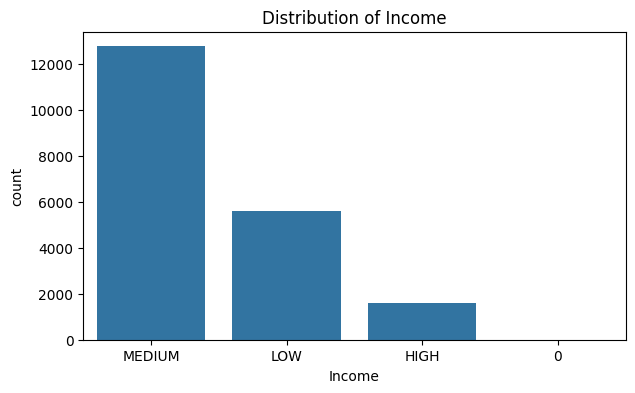

In [ ]:
for col in df.select_dtypes(include = 'object').columns:
  plt.figure(figsize = (7, 4))
  sns.countplot(data = df, x = col)
  plt.title(f'Distribution of {col}')
  plt.show()

In [ ]:
# bivariate analysis:
# check num cols vs cc_cons
# check cat cols vs cc_cons

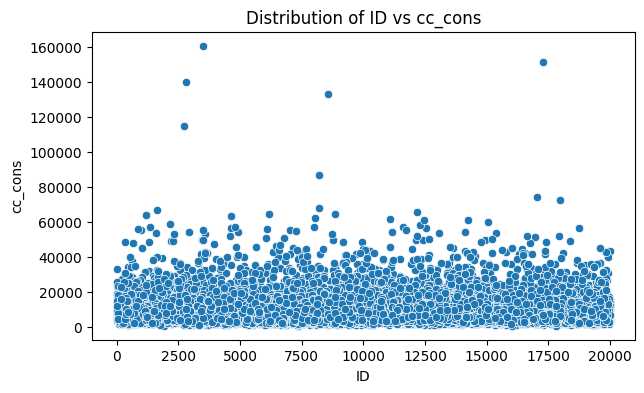

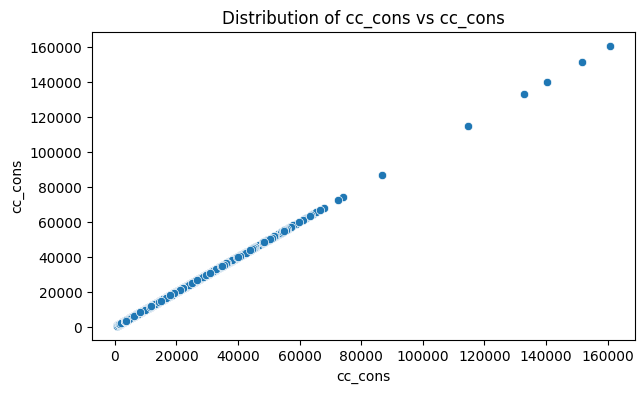

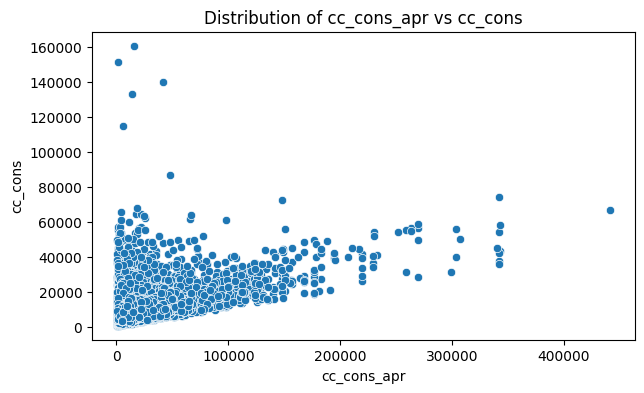

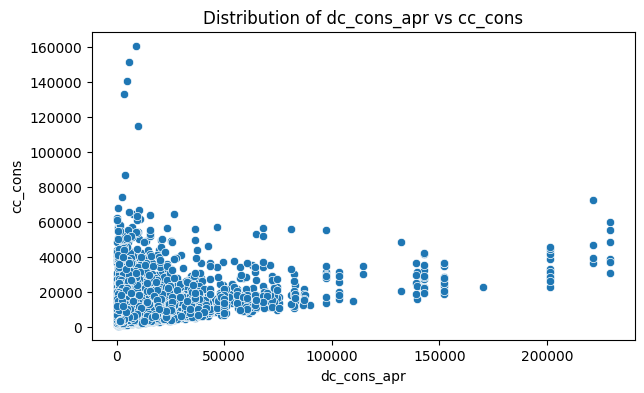

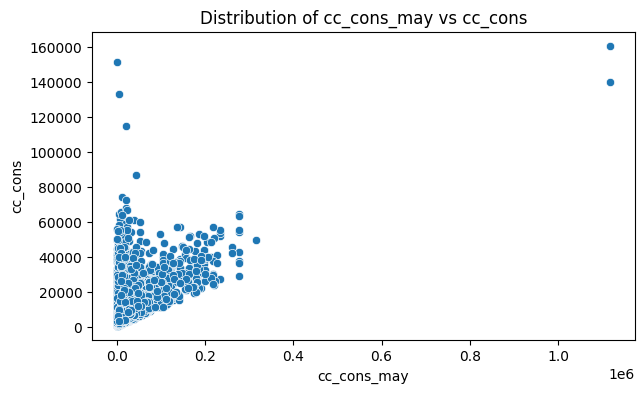

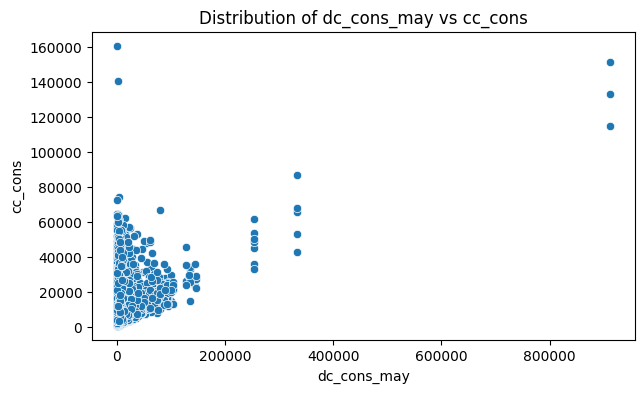

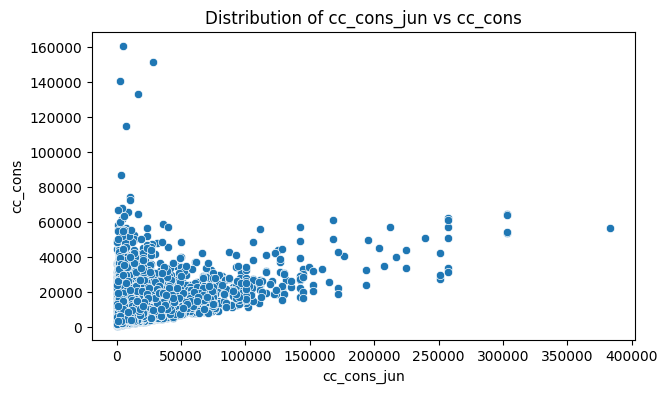

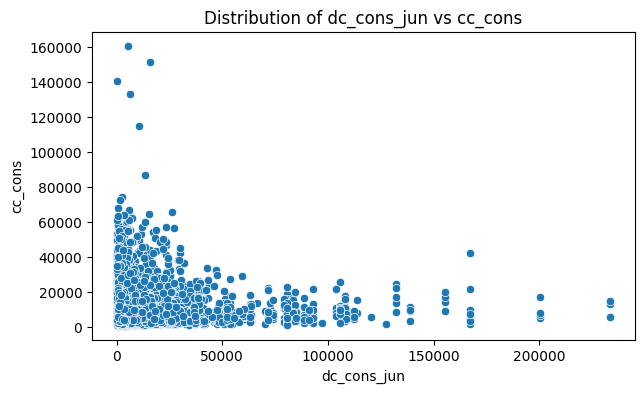

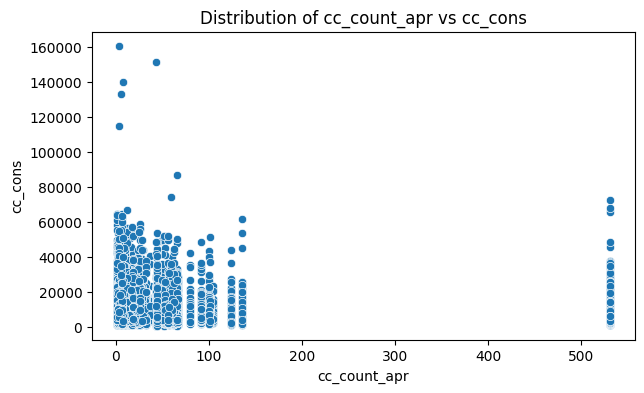

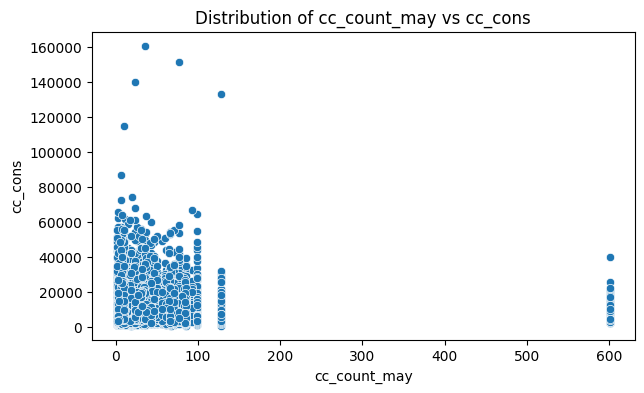

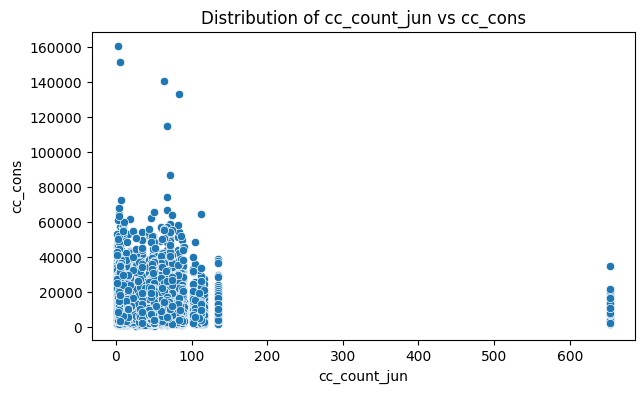

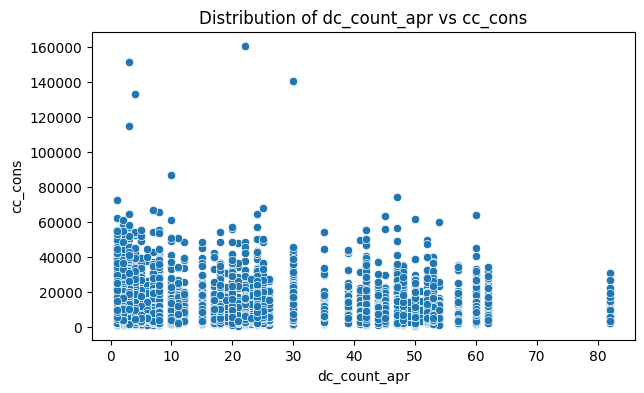

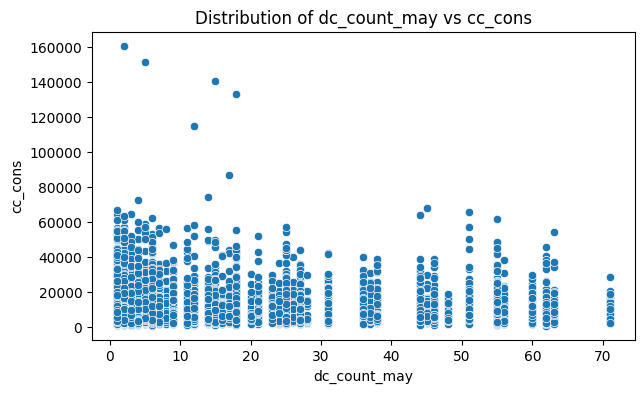

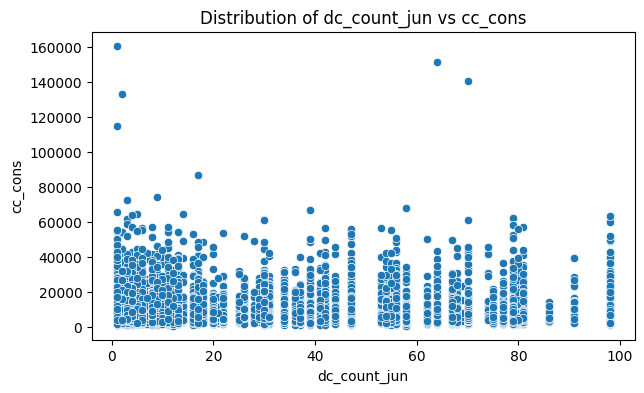

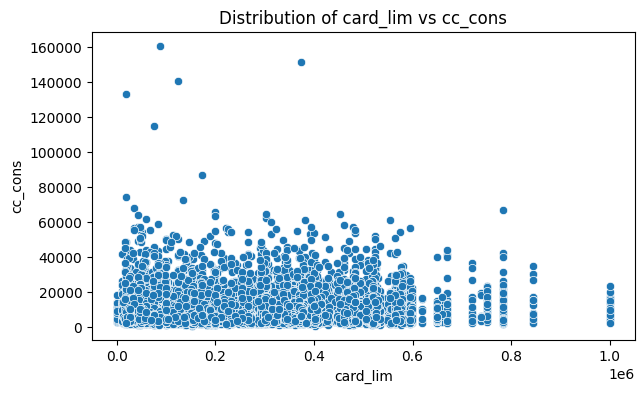

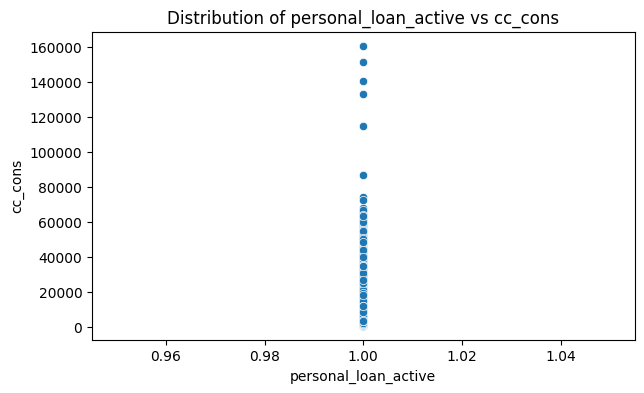

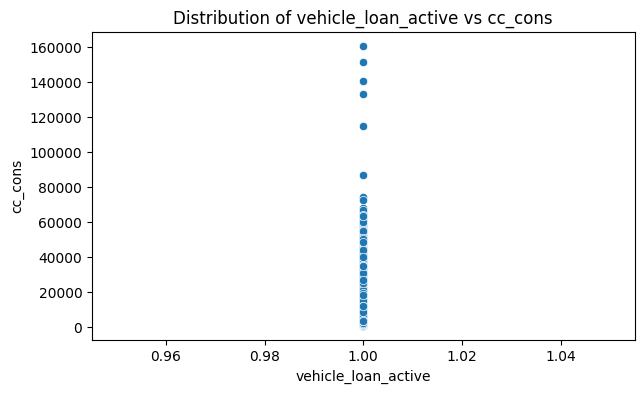

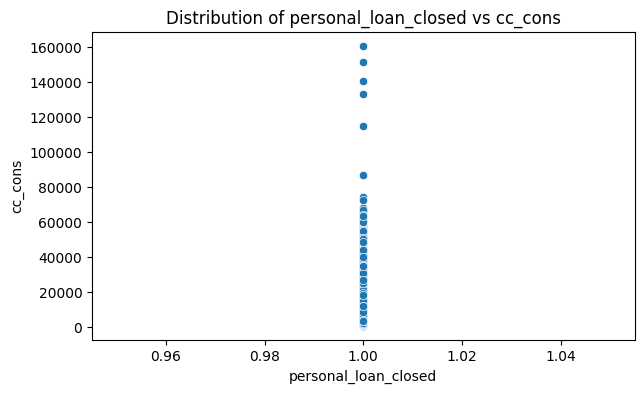

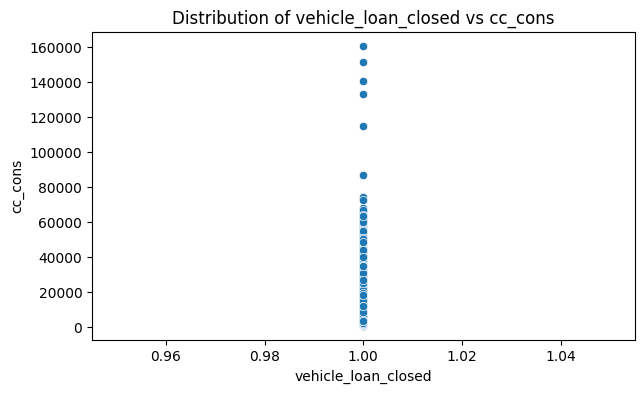

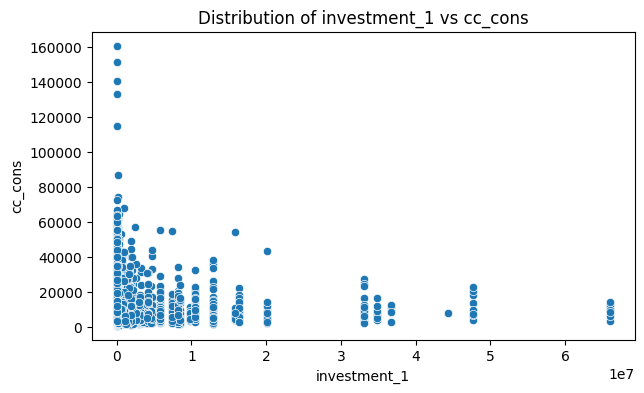

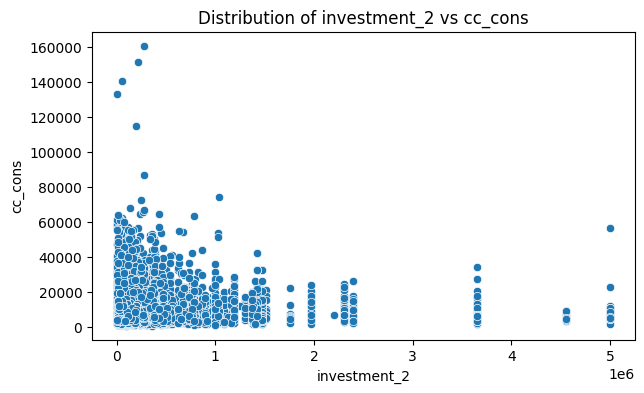

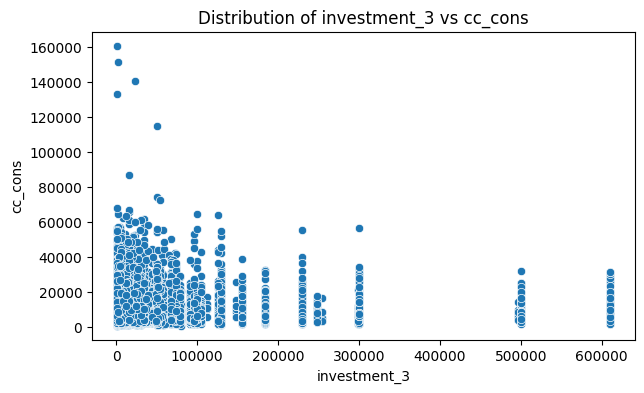

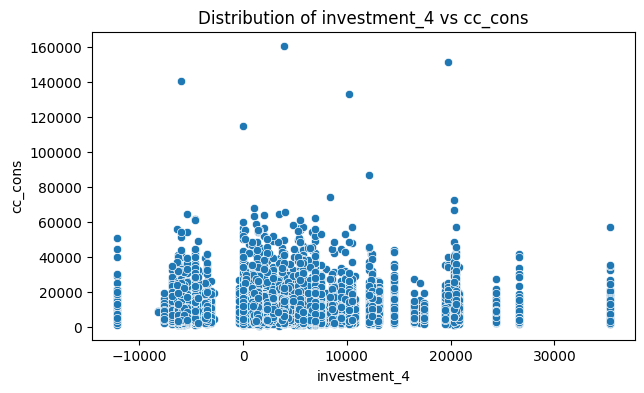

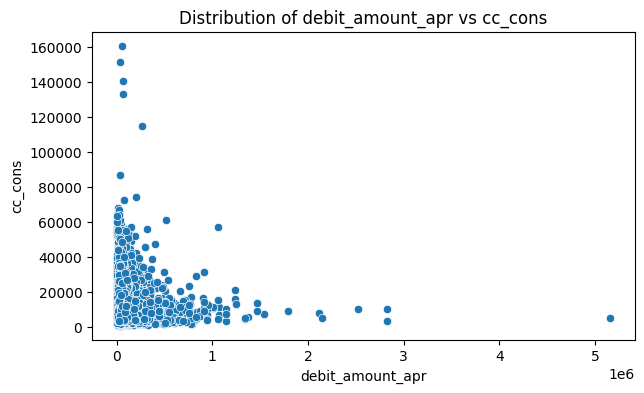

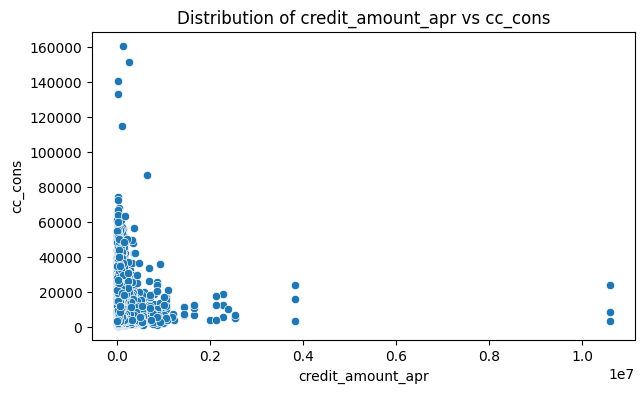

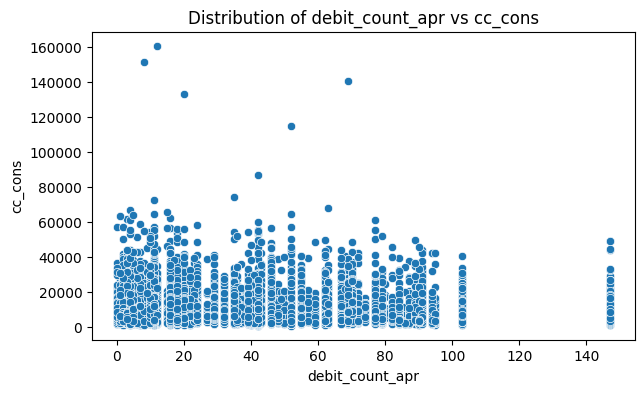

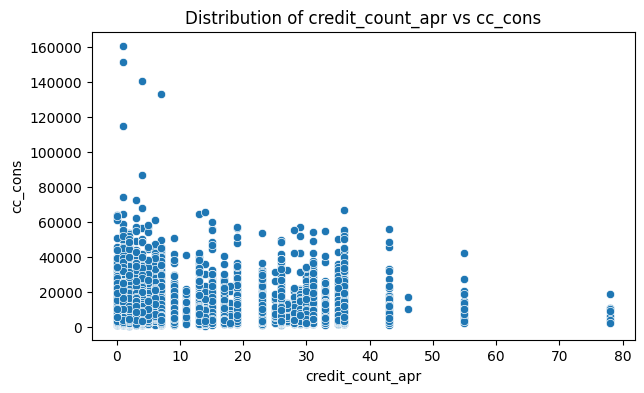

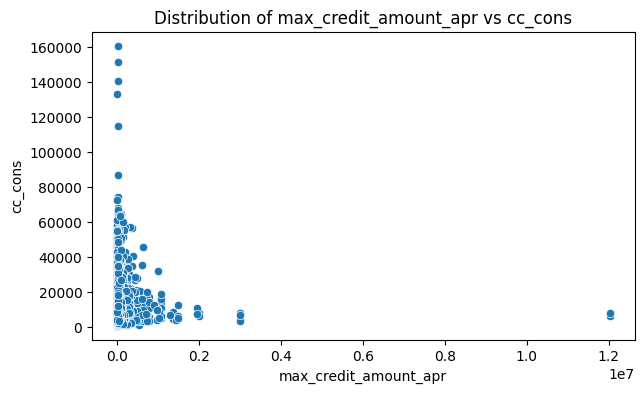

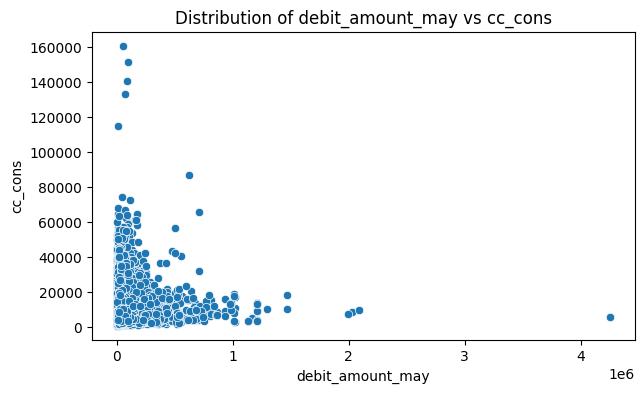

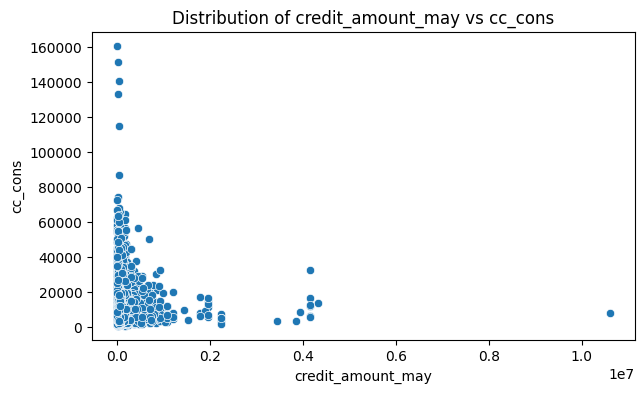

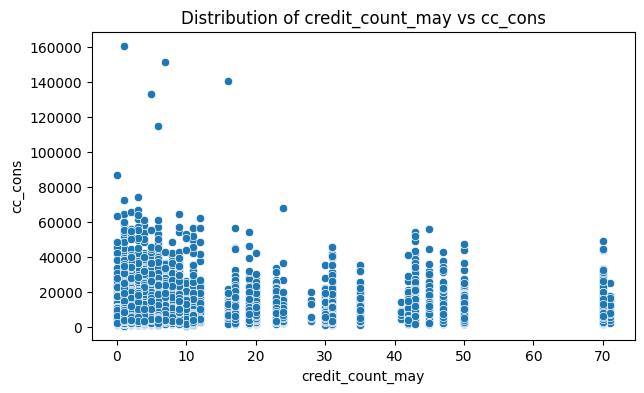

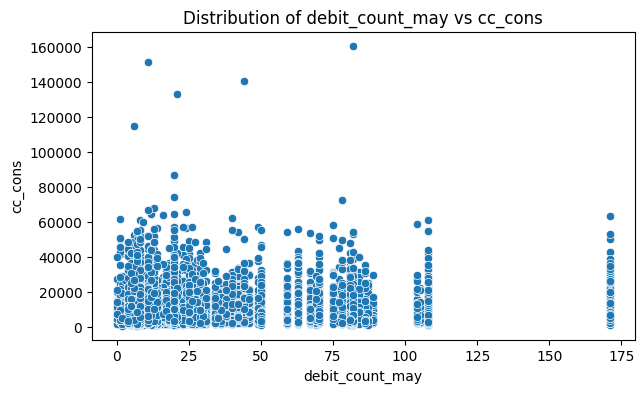

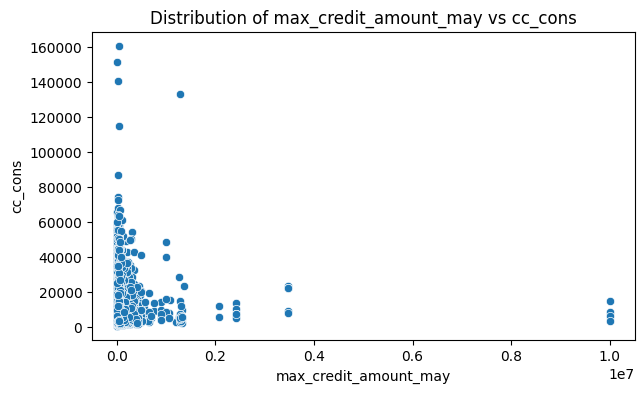

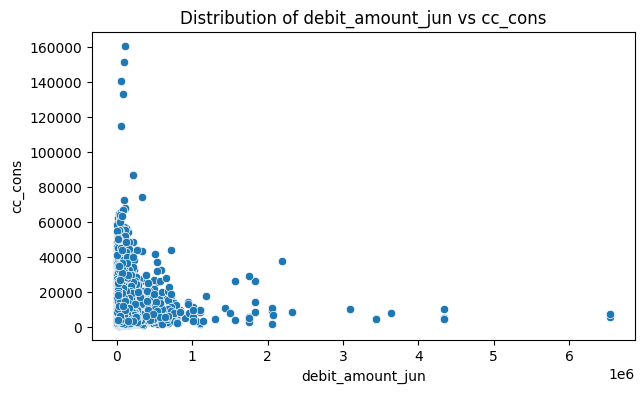

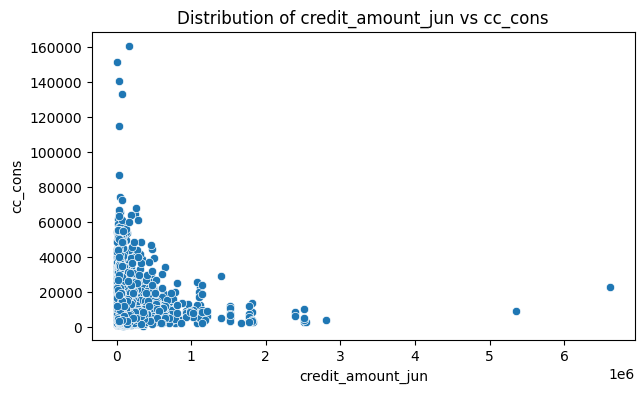

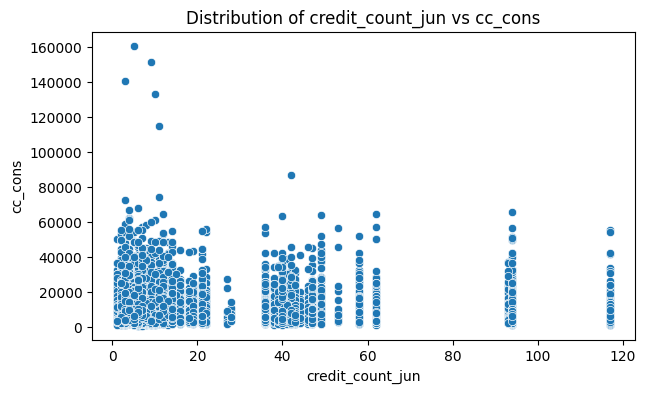

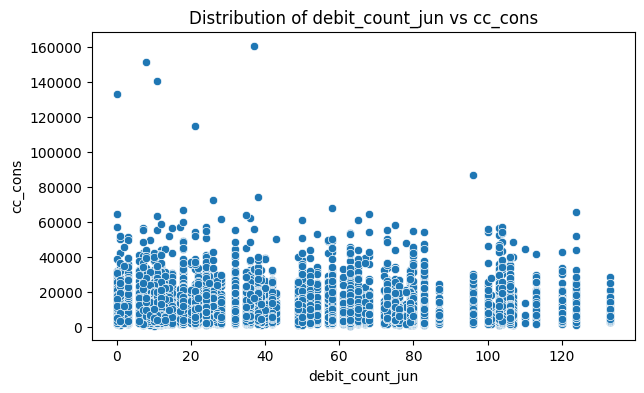

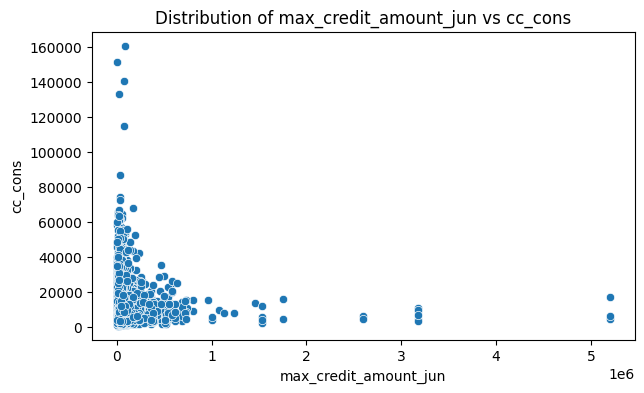

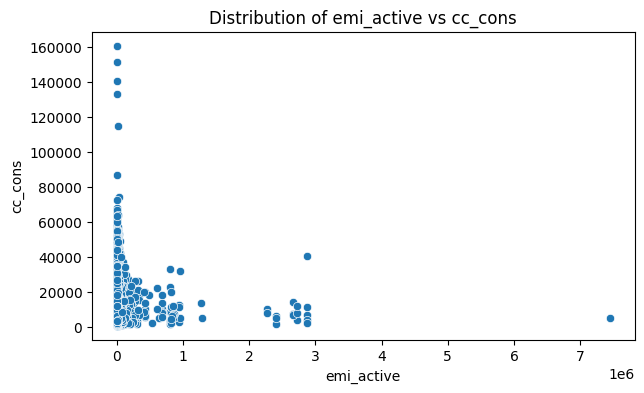

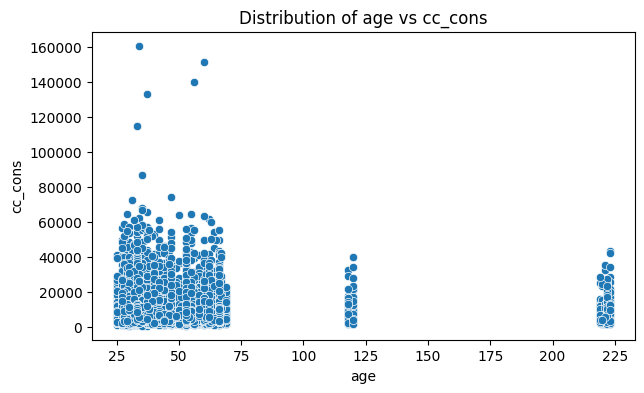

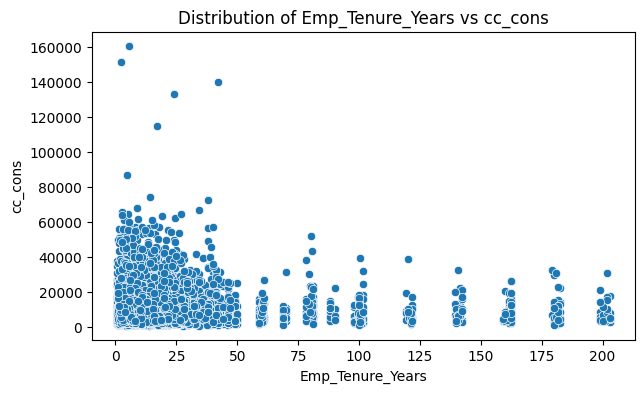

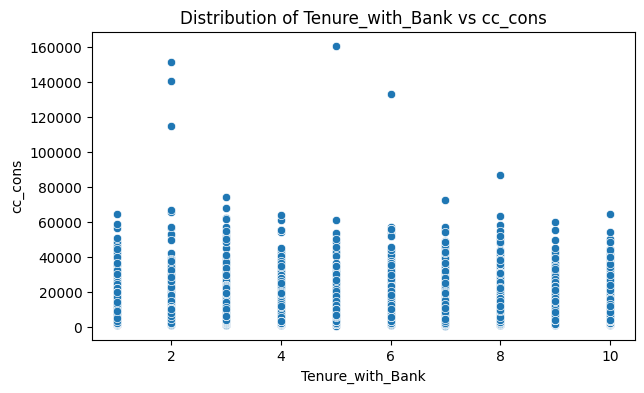

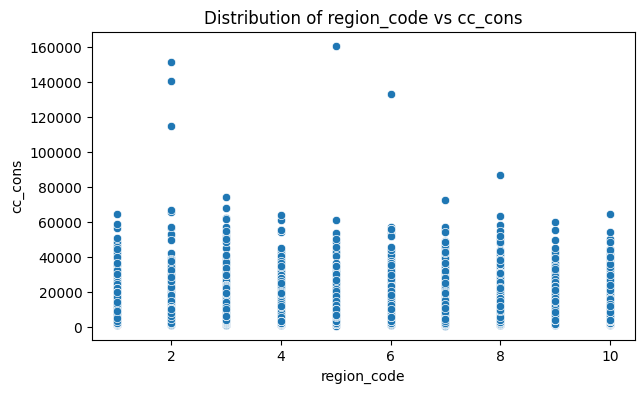

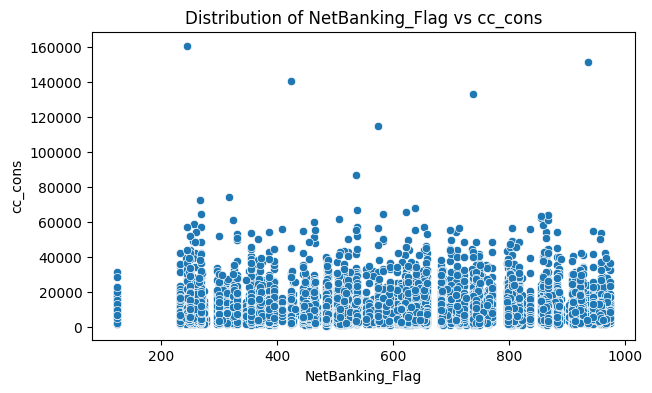

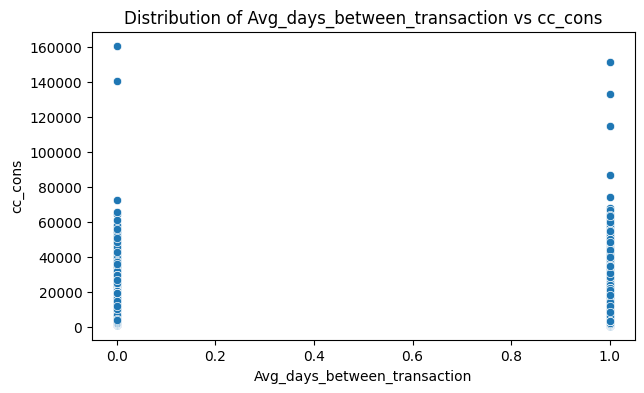

In [ ]:
for col in df.select_dtypes(include = 'number').columns:
  plt.figure(figsize = (7, 4))
  sns.scatterplot(data = df, x = col, y = 'cc_cons')
  plt.title(f'Distribution of {col} vs cc_cons')
  plt.show()

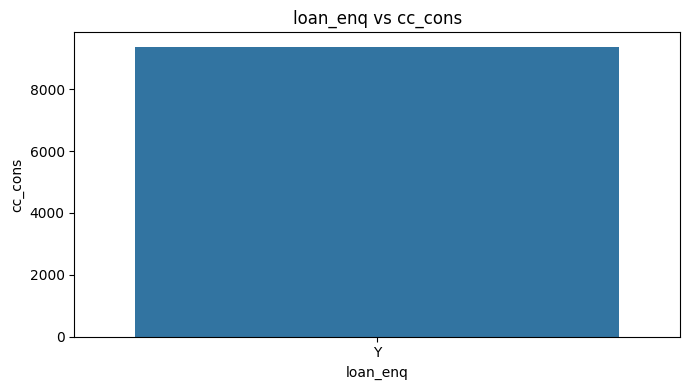

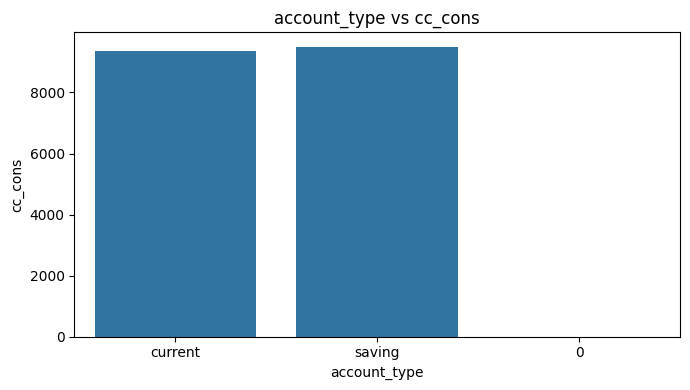

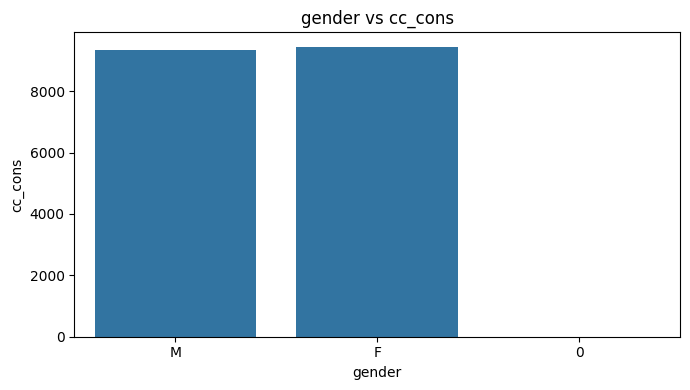

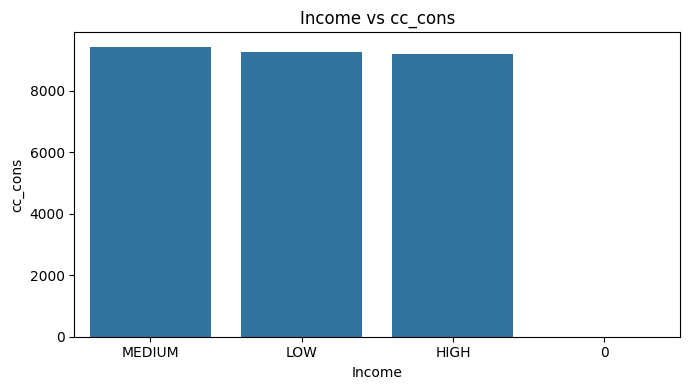

In [ ]:
for col in df.select_dtypes(include = 'object').columns:
  plt.figure(figsize = (7,4))
  sns.barplot(data = df, x = col, y = 'cc_cons', errorbar = None)
  plt.title(f'{col} vs cc_cons')
  plt.tight_layout()
  plt.show()

In [ ]:
# correlation among the numerical features

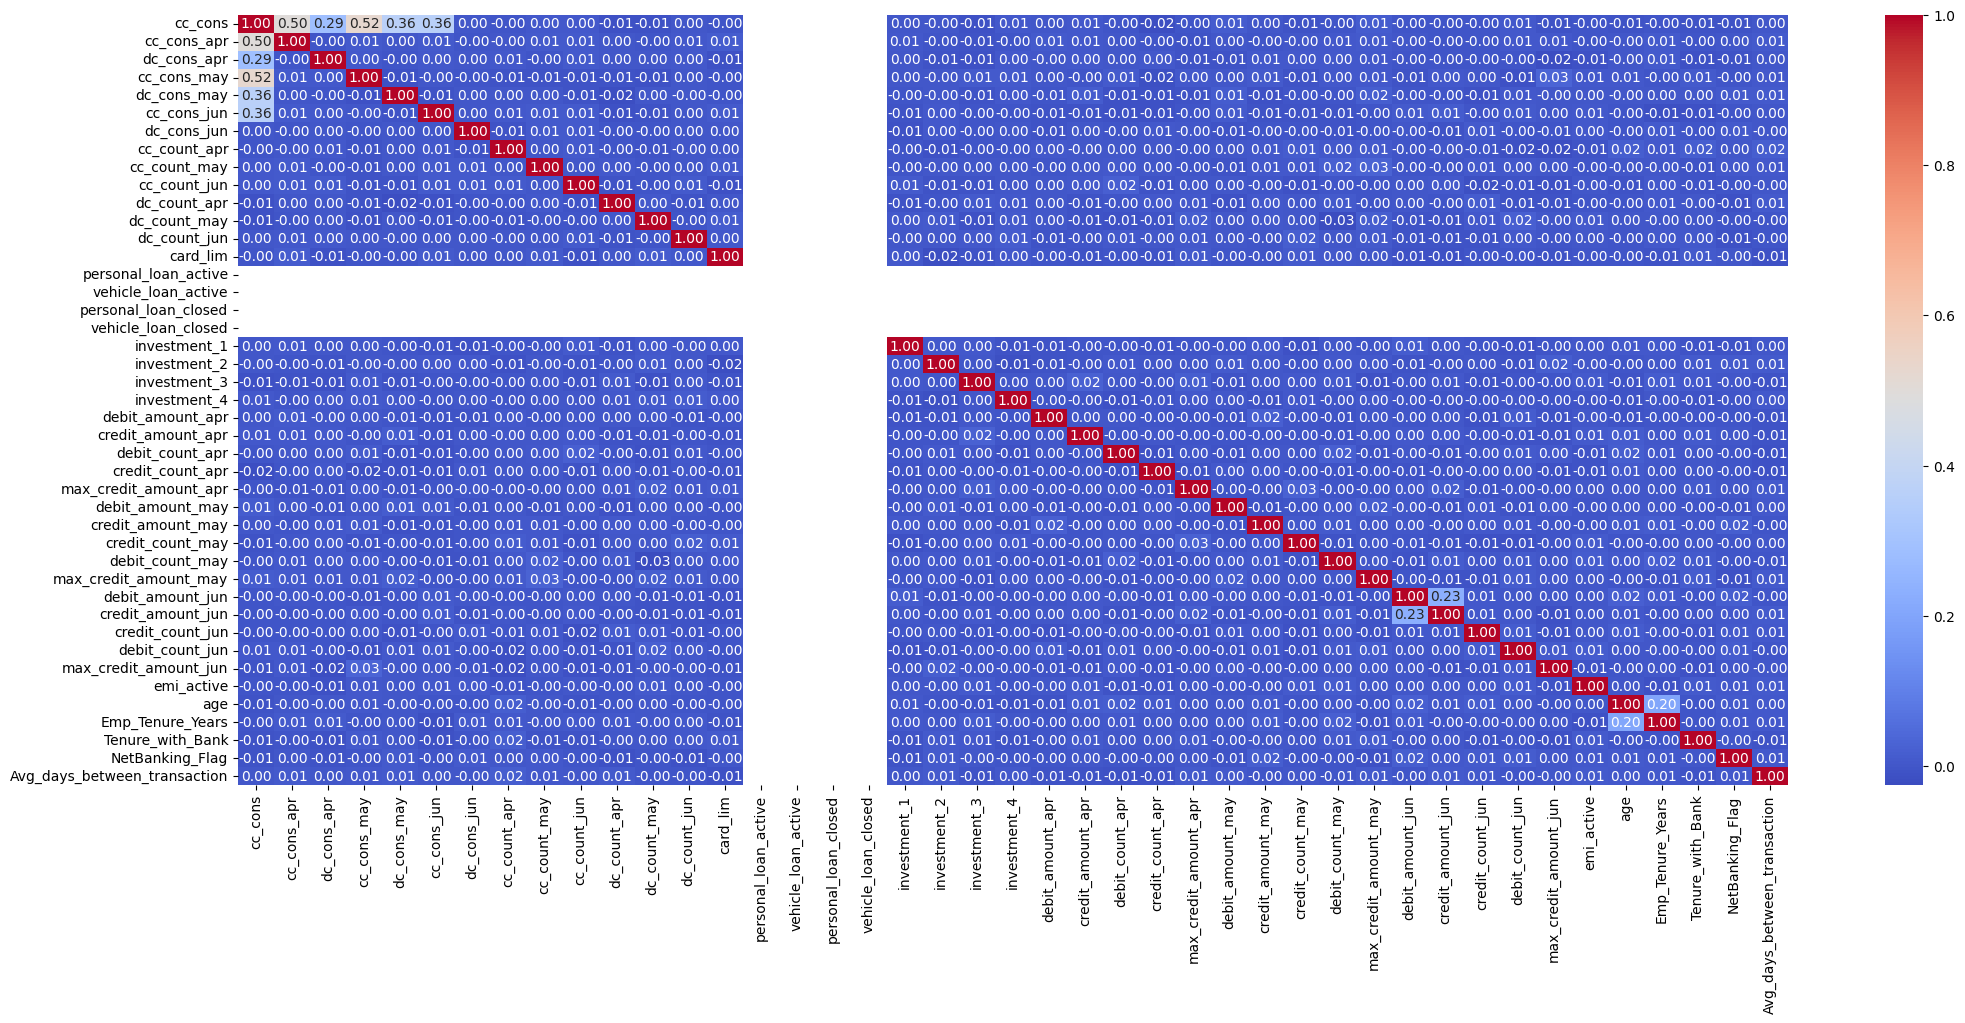

In [ ]:
plt.figure(figsize = (25, 10))
sns.heatmap(df.select_dtypes(include = 'number').drop(columns = ['ID', 'region_code']).corr(), annot = True, fmt = '.2f', cmap = 'coolwarm')
plt.show()

In [ ]:
# vidualize the distribution of the traget variable

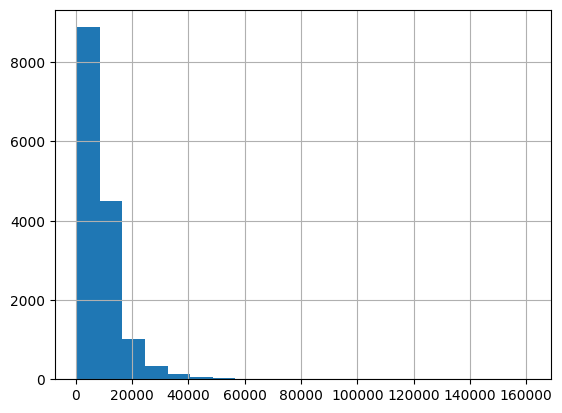

In [ ]:
df.cc_cons.hist(bins = 20)
plt.show()

In [ ]:
# Delete the columns with no varaince:
#'personal_loan_active',
#'vehicle_loan_active',
#'personal_loan_closed',
#'vehicle_loan_closed',
#'loan_enq'

In [ ]:
df.drop(columns = ['personal_loan_active','vehicle_loan_active','personal_loan_closed','vehicle_loan_closed','loan_enq'], inplace = True)

In [ ]:
df.columns

Index(['ID', 'cc_cons', 'cc_cons_apr', 'dc_cons_apr', 'cc_cons_may',
       'dc_cons_may', 'cc_cons_jun', 'dc_cons_jun', 'cc_count_apr',
       'cc_count_may', 'cc_count_jun', 'dc_count_apr', 'dc_count_may',
       'dc_count_jun', 'card_lim', 'investment_1', 'investment_2',
       'investment_3', 'investment_4', 'debit_amount_apr', 'credit_amount_apr',
       'debit_count_apr', 'credit_count_apr', 'max_credit_amount_apr',
       'debit_amount_may', 'credit_amount_may', 'credit_count_may',
       'debit_count_may', 'max_credit_amount_may', 'debit_amount_jun',
       'credit_amount_jun', 'credit_count_jun', 'debit_count_jun',
       'max_credit_amount_jun', 'emi_active', 'account_type', 'gender', 'age',
       'Income', 'Emp_Tenure_Years', 'Tenure_with_Bank', 'region_code',
       'NetBanking_Flag', 'Avg_days_between_transaction'],
      dtype='object')

In [ ]:
# separate the df into the set that will be used for training and validation and the one for predicting

In [ ]:
final_df = df[df.cc_cons.notna()].copy()
predict = df[df.cc_cons.isna()].copy()

In [ ]:
final_df.head()

,ID,cc_cons,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,...,emi_active,account_type,gender,age,Income,Emp_Tenure_Years,Tenure_with_Bank,region_code,NetBanking_Flag,Avg_days_between_transaction
0,17051,16239.0,2017.46,29066.66,15919.84,2197.00,3752.000,29798.00,1.0,4,...,3448.84,current,M,30,MEDIUM,26.4,9,9,355,0
1,11491,39002.0,7687.00,1308.00,41888.92,2216.92,7060.530,3143.36,2.0,27,...,3812.69,current,M,37,LOW,14.4,7,7,485,0
2,7433,21182.0,9094.46,14825.95,3087.64,769.59,25602.595,1445.00,44.0,8,...,9432.90,current,M,33,MEDIUM,3.2,1,1,764,0
3,14606,8123.0,3126.00,4616.33,8676.80,5923.00,6717.000,18747.00,4.0,30,...,144.61,current,M,63,LOW,10.2,6,6,863,0
4,8381,28282.0,24988.72,10091.23,10132.00,3477.00,4667.000,511.00,2.0,8,...,1887.89,saving,M,33,MEDIUM,26.4,6,6,523,0


In [ ]:
predict.head()

,ID,cc_cons,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,...,emi_active,account_type,gender,age,Income,Emp_Tenure_Years,Tenure_with_Bank,region_code,NetBanking_Flag,Avg_days_between_transaction
15000,17591,NaN,2795.45,1290.0,6141.05,676.50,9146.10,15479.00,4.0,10,...,1170.49,current,M,37,MEDIUM,11.9,4,4,575,1
15001,13541,NaN,29405.13,1640.0,1670.00,2463.92,10947.50,956.00,3.0,10,...,16447.45,current,M,33,MEDIUM,7.8,6,6,394,0
15002,13431,NaN,5985.20,6189.0,2696.09,766.00,716.00,4133.22,7.0,30,...,2622.28,current,M,53,LOW,33.0,10,10,324,1
15003,8687,NaN,2105.93,18225.0,34763.56,167.00,4260.27,20185.00,1.0,99,...,340.79,current,M,33,MEDIUM,7.8,5,5,370,1
15004,14727,NaN,3269.00,3532.0,3158.40,2699.77,3373.48,5120.00,2.0,10,...,2812.20,current,M,62,LOW,12.6,9,9,505,1


In [ ]:
final_df.isna().sum()

,0
ID,0
cc_cons,0
cc_cons_apr,0
dc_cons_apr,0
cc_cons_may,0
dc_cons_may,1
cc_cons_jun,0
dc_cons_jun,0
cc_count_apr,1
cc_count_may,0


In [ ]:
# no null values for cc_cons

In [ ]:
predict.isna().sum()

,0
ID,0
cc_cons,5000
cc_cons_apr,0
dc_cons_apr,0
cc_cons_may,1
dc_cons_may,0
cc_cons_jun,0
dc_cons_jun,1
cc_count_apr,0
cc_count_may,0


In [ ]:
# all null values for cc_cons

In [ ]:
# separate the predictor and target values in final_df

In [ ]:
X = final_df.drop(columns = ['ID', 'cc_cons'])
y = final_df.cc_cons

In [ ]:
# split into train and validation sets

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 123)

In [ ]:
# check the shapes

In [ ]:
X_train.shape

(12000, 42)

In [ ]:
X_test.shape

(3000, 42)

In [ ]:
y_train.shape

(12000,)

In [ ]:
y_test.shape

(3000,)

In [ ]:
# separate the cat cols and num cols

In [ ]:
num_cols = X_train.select_dtypes(include = 'number').columns
cat_cols = X_train.select_dtypes(include = 'object').columns

In [ ]:
num_cols = ['cc_cons_apr', 'dc_cons_apr', 'cc_cons_may', 'dc_cons_may',
       'cc_cons_jun', 'dc_cons_jun', 'cc_count_apr', 'cc_count_may',
       'cc_count_jun', 'dc_count_apr', 'dc_count_may', 'dc_count_jun',
       'card_lim', 'investment_1', 'investment_2', 'investment_3',
       'investment_4', 'debit_amount_apr', 'credit_amount_apr',
       'debit_count_apr', 'credit_count_apr', 'max_credit_amount_apr',
       'debit_amount_may', 'credit_amount_may', 'credit_count_may',
       'debit_count_may', 'max_credit_amount_may', 'debit_amount_jun',
       'credit_amount_jun', 'credit_count_jun', 'debit_count_jun',
       'max_credit_amount_jun', 'emi_active', 'age', 'Emp_Tenure_Years',
       'Tenure_with_Bank', 'NetBanking_Flag',
       'Avg_days_between_transaction']

In [ ]:
cat_cols = ['account_type', 'gender', 'Income', 'region_code']

In [ ]:
X_train_num = X_train[num_cols]
X_test_num = X_test[num_cols]
X_train_cat = X_train[cat_cols]
X_test_cat = X_test[cat_cols]

In [ ]:
# impute missing values

In [ ]:
knn = KNNImputer()

In [ ]:
X_train_num = pd.DataFrame(knn.fit_transform(X_train_num), columns = X_train_num.columns, index = X_train_num.index)
X_test_num = pd.DataFrame(knn.transform(X_test_num), columns = X_test_num.columns, index = X_test_num.index)

In [ ]:
for col in X_train_cat.columns:
  print(X_train_cat[col].value_counts())

account_type
current    10162
saving      1838
Name: count, dtype: int64
gender
M    10374
F     1626
Name: count, dtype: int64
Income
MEDIUM    7678
LOW       3366
HIGH       956
Name: count, dtype: int64
region_code
7     1263
10    1229
6     1225
2     1215
4     1199
8     1194
1     1175
9     1172
3     1164
5     1164
Name: count, dtype: int64


In [ ]:
X_train_cat = X_train_cat.replace(0, np.nan)
X_test_cat = X_test_cat.replace(0, np.nan)

In [ ]:
X_train_cat.isna().sum()

,0
account_type,0
gender,0
Income,0
region_code,0


In [ ]:
simple = SimpleImputer(strategy = 'most_frequent')

In [ ]:
X_train_cat = pd.DataFrame(simple.fit_transform(X_train_cat), columns = X_train_cat.columns, index = X_train_cat.index)
X_test_cat = pd.DataFrame(simple.transform(X_test_cat), columns = X_test_cat.columns, index = X_test_cat.index)

In [ ]:
# outliers treatment

In [ ]:
def outliers_cap(train, test):
  lower = train.quantile(0.01)
  upper = train.quantile(0.99)

  train = train.clip(upper = upper, lower = lower, axis = 1)
  test = test.clip(upper = upper, lower = lower, axis = 1)

  return train, test

In [ ]:
X_train_num, X_test_num = outliers_cap(X_train_num, X_test_num)

In [ ]:
# encode the categorical features

In [ ]:
for col in X_train_cat.columns:
  print(X_train_cat[col].value_counts())

account_type
current    10162
saving      1838
Name: count, dtype: int64
gender
M    10374
F     1626
Name: count, dtype: int64
Income
MEDIUM    7678
LOW       3366
HIGH       956
Name: count, dtype: int64
region_code
7     1263
10    1229
6     1225
2     1215
4     1199
8     1194
1     1175
9     1172
3     1164
5     1164
Name: count, dtype: int64


In [ ]:
# encode income using ordinal encoding

In [ ]:
order = [['LOW', 'MEDIUM', "HIGH"]]
income_encoder = OrdinalEncoder(categories = order)
X_train_income = income_encoder.fit_transform(X_train_cat[['Income']])
X_test_income = income_encoder.transform(X_test_cat[['Income']])

In [ ]:
X_train_income = pd.DataFrame(X_train_income, columns = ['Income'], index = X_train_cat['Income'].index)
X_test_income = pd.DataFrame(X_test_income, columns = ['Income'], index = X_test_cat['Income'].index)

In [ ]:
# apply one hot encoding to the rest of the columns

In [ ]:
ohe = OneHotEncoder(handle_unknown = 'ignore', sparse_output = False)

In [ ]:
ohe_cols = ['account_type', 'gender', 'region_code']

X_train_ohe = ohe.fit_transform(X_train_cat[ohe_cols])
X_test_ohe = ohe.transform(X_test_cat[ohe_cols])

In [ ]:
X_train_ohe = pd.DataFrame(X_train_ohe, columns = ohe.get_feature_names_out(ohe_cols), index = X_train_cat.index)
X_test_ohe = pd.DataFrame(X_test_ohe, columns = ohe.get_feature_names_out(ohe_cols), index = X_test_cat.index)

In [ ]:
# combine the X features

In [ ]:
X_train = pd.concat([X_train_num, X_train_income, X_train_ohe],axis = 1)
X_test = pd.concat([X_test_num, X_test_income, X_test_ohe], axis = 1)

In [ ]:
X_train.head()

,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,...,region_code_1,region_code_2,region_code_3,region_code_4,region_code_5,region_code_6,region_code_7,region_code_8,region_code_9,region_code_10
3553,13244.28,13543.00,10007.43,16828.00,14108.00,5356.52,7.0,9.0,35.0,15.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2112,5737.00,2814.00,11518.64,7782.00,18304.59,9530.01,26.0,46.0,6.0,48.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1794,31691.00,3884.65,1539.00,14556.00,20688.50,9270.00,5.0,23.0,30.0,44.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
13886,9203.73,21265.70,11357.81,5416.40,14989.48,4516.00,10.0,5.0,50.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
11251,14872.69,18197.05,3748.00,9447.93,9920.00,4275.00,124.0,10.0,44.0,2.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [ ]:
X_test.head()

,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,...,region_code_1,region_code_2,region_code_3,region_code_4,region_code_5,region_code_6,region_code_7,region_code_8,region_code_9,region_code_10
6958,38439.19,8615.96,21118.50,1733.86,14969.00,1826.00,5.0,2.0,44.0,17.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
7534,10684.49,457.00,4082.30,2188.50,6110.00,3800.79,5.0,13.0,87.0,24.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2975,4211.76,5574.20,31677.17,231.00,8953.00,1421.66,2.0,77.0,29.0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3903,1975.50,461.00,14010.00,3447.00,431.00,21189.30,10.0,50.0,13.0,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8437,13129.67,18340.00,15708.01,463.00,1587.73,1630.00,6.0,10.0,86.0,41.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [ ]:
rf = RandomForestRegressor(n_estimators = 50, max_depth = 10, random_state = 123, n_jobs = -1)

In [ ]:
rfe = RFE(estimator = rf, n_features_to_select = 15, step = 5)

In [ ]:
rfe.fit(X_train, y_train)

RFE(estimator=RandomForestRegressor(max_depth=10, n_estimators=50, n_jobs=-1,
                                    random_state=123),
    n_features_to_select=15, step=5)

In [ ]:
sel_cols = X_train.columns[rfe.support_]

In [ ]:
sel_cols


Index(['cc_cons_apr', 'dc_cons_apr', 'cc_cons_may', 'dc_cons_may',
       'cc_cons_jun', 'dc_cons_jun', 'cc_count_may', 'dc_count_jun',
       'card_lim', 'max_credit_amount_apr', 'max_credit_amount_may',
       'credit_amount_jun', 'max_credit_amount_jun', 'emi_active',
       'NetBanking_Flag'],
      dtype='object')

In [ ]:
rfe.ranking_

array([1, 1, 1, 1, 1, 1, 4, 1, 4, 6, 4, 1, 1, 5, 3, 6, 5, 2, 5, 4, 5, 1,
       2, 3, 5, 3, 1, 3, 1, 6, 3, 1, 1, 7, 4, 6, 1, 7, 6, 9, 7, 9, 7, 8,
       8, 7, 8, 2, 9, 9, 8, 8, 9])

In [ ]:
# use gcv for hyper paramater tuning

In [ ]:
param_grid = {'max_depth':[2,3,5], 'max_features':[2,3,5], 'n_estimators': [10], 'max_leaf_nodes':[3,4],'min_samples_split':[2,3,5], 'min_samples_leaf':[2,3,5]}

In [ ]:
gcv = GridSearchCV(estimator = rf, param_grid = param_grid, cv = 5, n_jobs = -1, verbose = True)

In [ ]:
gcv.fit(X_train[sel_cols], y_train)

Fitting 5 folds for each of 162 candidates, totalling 810 fits


GridSearchCV(cv=5,
             estimator=RandomForestRegressor(max_depth=10, n_estimators=50,
                                             n_jobs=-1, random_state=123),
             n_jobs=-1,
             param_grid={'max_depth': [2, 3, 5], 'max_features': [2, 3, 5],
                         'max_leaf_nodes': [3, 4],
                         'min_samples_leaf': [2, 3, 5],
                         'min_samples_split': [2, 3, 5], 'n_estimators': [10]},
             verbose=True)

In [ ]:
gcv.best_score_

np.float64(0.394858952420747)

In [ ]:
gcv.best_params_

{'max_depth': 3,
 'max_features': 5,
 'max_leaf_nodes': 4,
 'min_samples_leaf': 3,
 'min_samples_split': 2,
 'n_estimators': 10}

In [ ]:
gcv.cv_results_

{'mean_fit_time': array([0.10266547, 0.08145046, 0.08027787, 0.08123174, 0.07079229,
        0.0661366 , 0.07584248, 0.0724082 , 0.06308165, 0.07028775,
        0.0795032 , 0.07350569, 0.06921754, 0.08767886, 0.12564583,
        0.1259583 , 0.13018823, 0.16652555, 0.17334948, 0.15028558,
        0.18268261, 0.19593425, 0.17705083, 0.16732259, 0.15904503,
        0.11374655, 0.08659463, 0.08988676, 0.09978409, 0.10248637,
        0.08869739, 0.10200124, 0.09206624, 0.10005493, 0.09629378,
        0.10028181, 0.13478274, 0.13816028, 0.13877916, 0.14356251,
        0.11679025, 0.13136945, 0.13791189, 0.1314292 , 0.13890781,
        0.13584814, 0.12276483, 0.13072062, 0.11598544, 0.12134295,
        0.126156  , 0.12442818, 0.12679634, 0.13950958, 0.13906164,
        0.15078402, 0.1626544 , 0.15840454, 0.13441525, 0.1441    ,
        0.15397606, 0.15417905, 0.14644408, 0.13276424, 0.13833041,
        0.13701105, 0.07670279, 0.08370357, 0.08263736, 0.08026443,
        0.06758399, 0.07672262,

In [ ]:
rf = gcv.best_estimator_

In [ ]:
rf.fit(X_train[sel_cols], y_train)

RandomForestRegressor(max_depth=3, max_features=5, max_leaf_nodes=4,
                      min_samples_leaf=3, n_estimators=10, n_jobs=-1,
                      random_state=123)

In [ ]:
y_pred = rf.predict(X_test[sel_cols])

In [ ]:
print(f'MSE: {mean_squared_error(y_test, y_pred)}')
print(f'RMSE: {np.sqrt(mean_squared_error(y_test, y_pred))}')
print(f'f"Root Mean Squared Percentage Error: {np.sqrt(
    np.mean(((y_test - y_pred) / y_test) ** 2)
) * 100}')

MSE: 41532263.126195215
RMSE: 6444.552981099248
f"Root Mean Squared Percentage Error: 97.46106683758607


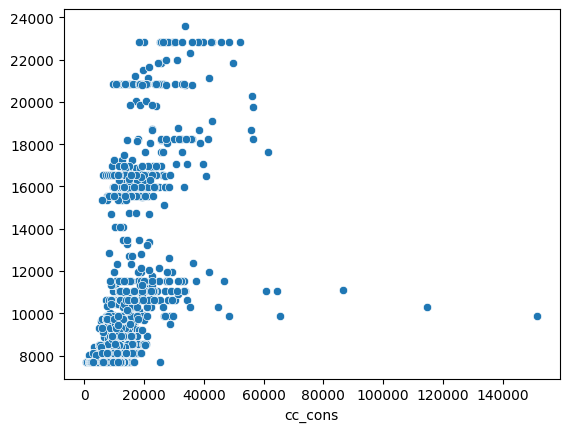

In [ ]:
sns.scatterplot(x = y_test, y = y_pred)
plt.show()

In [ ]:
# load test data and perform preprocessing

In [ ]:
predict.head()

,ID,cc_cons,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,...,emi_active,account_type,gender,age,Income,Emp_Tenure_Years,Tenure_with_Bank,region_code,NetBanking_Flag,Avg_days_between_transaction
15000,17591,NaN,2795.45,1290.0,6141.05,676.50,9146.10,15479.00,4.0,10,...,1170.49,current,M,37,MEDIUM,11.9,4,4,575,1
15001,13541,NaN,29405.13,1640.0,1670.00,2463.92,10947.50,956.00,3.0,10,...,16447.45,current,M,33,MEDIUM,7.8,6,6,394,0
15002,13431,NaN,5985.20,6189.0,2696.09,766.00,716.00,4133.22,7.0,30,...,2622.28,current,M,53,LOW,33.0,10,10,324,1
15003,8687,NaN,2105.93,18225.0,34763.56,167.00,4260.27,20185.00,1.0,99,...,340.79,current,M,33,MEDIUM,7.8,5,5,370,1
15004,14727,NaN,3269.00,3532.0,3158.40,2699.77,3373.48,5120.00,2.0,10,...,2812.20,current,M,62,LOW,12.6,9,9,505,1


In [ ]:
predict.isna().sum()

,0
ID,0
cc_cons,5000
cc_cons_apr,0
dc_cons_apr,0
cc_cons_may,1
dc_cons_may,0
cc_cons_jun,0
dc_cons_jun,1
cc_count_apr,0
cc_count_may,0


In [ ]:
predict = df[df.cc_cons.isna()].copy()

In [ ]:
predid = predict['ID']


In [ ]:
predict = predict.drop(columns = ['ID'])

In [ ]:
id

,ID
15000,17591
15001,13541
15002,13431
15003,8687
15004,14727
...,...
19995,12512
19996,14224
19997,18740
19998,18134


In [ ]:
y = predict['cc_cons']

In [ ]:
X = predict.drop(columns = ['cc_cons'])

In [ ]:
cat_pred = predict.select_dtypes(include = 'object').columns
num_pred = predict.select_dtypes(include = 'number').columns

In [ ]:
num_pred = ['cc_cons_apr', 'dc_cons_apr', 'cc_cons_may', 'dc_cons_may',
       'cc_cons_jun', 'dc_cons_jun', 'cc_count_apr', 'cc_count_may',
       'cc_count_jun', 'dc_count_apr', 'dc_count_may', 'dc_count_jun',
       'card_lim', 'investment_1', 'investment_2', 'investment_3',
       'investment_4', 'debit_amount_apr', 'credit_amount_apr',
       'debit_count_apr', 'credit_count_apr', 'max_credit_amount_apr',
       'debit_amount_may', 'credit_amount_may', 'credit_count_may',
       'debit_count_may', 'max_credit_amount_may', 'debit_amount_jun',
       'credit_amount_jun', 'credit_count_jun', 'debit_count_jun',
       'max_credit_amount_jun', 'emi_active', 'age', 'Emp_Tenure_Years',
       'Tenure_with_Bank', 'NetBanking_Flag',
       'Avg_days_between_transaction']

In [ ]:
cat_pred = ['account_type', 'gender', 'Income', 'region_code']

In [ ]:
X_num = X[num_pred]
X_cat = X[cat_pred]

In [ ]:
X_num.isna().sum()

,0
cc_cons_apr,0
dc_cons_apr,0
cc_cons_may,1
dc_cons_may,0
cc_cons_jun,0
dc_cons_jun,1
cc_count_apr,0
cc_count_may,0
cc_count_jun,0
dc_count_apr,0


In [ ]:
X_num = pd.DataFrame(knn.transform(X_num), columns = X_num.columns, index = X_num.index)

In [ ]:
lower = X_train_num.quantile(0.01)
upper = X_train_num.quantile(0.99)

X_num = X_num.clip(upper = upper, lower = lower, axis = 1)

In [ ]:
X_cat = X_cat.replace(0, np.nan)

In [ ]:
X_cat = pd.DataFrame(simple.transform(X_cat), columns = X_cat.columns, index = X_cat.index)

In [ ]:
X_cat_income = income_encoder.transform(X_cat[['Income']])
X_cat_income = pd.DataFrame(X_cat_income, columns = ['Income'], index = X_cat.index)

In [ ]:
X_cat_ohe = ohe.transform(X_cat[ohe_cols])
X_cat_ohe = pd.DataFrame(X_cat_ohe, columns = ohe.get_feature_names_out(ohe_cols), index = X_cat.index)

In [ ]:
X_pred = pd.concat([X_num, X_cat_income, X_cat_ohe], axis = 1)

In [ ]:
predictions = rf.predict(X_pred[sel_cols])

In [ ]:
predictions = pd.Series(predictions)

In [ ]:
submissions = pd.DataFrame({'ID':predid.values, 'cc_cons':predictions})

In [ ]:
submissions.head()

,ID,cc_cons
0,17591,7705.320272
1,13541,7705.320272
2,13431,7705.320272
3,8687,8121.408000
4,14727,7705.320272


In [ ]:
submissions.to_excel('/content/drive/My Drive/Analytix labs case studies/Credit Risk Analysis/submission.xlsx', index = False)